<center><h1>Kim_Beomjun_HW4</h1></center>
<br>
<br>

Name: Beomjun Kim 
<br>
Github Username: valen991693
<br>
USC ID: 4391-4935-38

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [111]:
from io import StringIO
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm

from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_score,
)
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    label_binarize,
    MinMaxScaler,
    StandardScaler,
)

warnings.filterwarnings("ignore", category=FutureWarning)

Get the AReM Data Set

In [ ]:
DATA_DIR = Path("../data")

activities = [
    "bending1",
    "bending2",
    "cycling",
    "lying",
    "sitting",
    "standing",
    "walking"
]

for activity in activities:
    files = sorted((DATA_DIR / activity).glob("dataset*.csv"))
    print(f"{activity}: {len(files)} datasets")

bending1: 7 datasets
bending2: 6 datasets
cycling: 15 datasets
lying: 15 datasets
sitting: 15 datasets
standing: 15 datasets
walking: 15 datasets


In [3]:
total_datasets = sum(
    len(list((DATA_DIR / activity).glob("dataset*.csv")))
    for activity in activities
)

print("Total number of datasets:", total_datasets)

Total number of datasets: 88


### (b) Splitting Data

In [4]:
train_files = []
test_files = []

for activity in activities:
    activity_dir = DATA_DIR / activity
    files = sorted(
        activity_dir.glob("dataset*.csv"),
        key=lambda x: int(x.stem.replace("dataset", ""))
    )

    for file_path in files:
        dataset_num = int(file_path.stem.replace("dataset", ""))

        if activity in ["bending1", "bending2"]:
            if dataset_num in [1, 2]:
                test_files.append((activity, file_path))
            else:
                train_files.append((activity, file_path))

        else:
            if dataset_num in [1, 2, 3]:
                test_files.append((activity, file_path))
            else:
                train_files.append((activity, file_path))

In [5]:
print("Number of training instances:", len(train_files))
print("Number of test instances:", len(test_files))
print("Total:", len(train_files) + len(test_files))

Number of training instances: 69
Number of test instances: 19
Total: 88


In [6]:
train_counts = {}
test_counts = {}

for activity in activities:
    train_counts[activity] = sum(
        1 for a, _ in train_files if a == activity
    )
    test_counts[activity] = sum(
        1 for a, _ in test_files if a == activity
    )

split_summary = pd.DataFrame({
    "Train": train_counts,
    "Test": test_counts
})

split_summary["Total"] = (
    split_summary["Train"] + split_summary["Test"]
)

split_summary

,Train,Test,Total
bending1,5,2,7
bending2,4,2,6
cycling,12,3,15
lying,12,3,15
sitting,12,3,15
standing,12,3,15
walking,12,3,15


### (c) Feature Extraction

#### i. Research

Common time-domain features used in time series classification include:

- Minimum and maximum
- Mean
- Median
- First and third quartiles
- Standard deviation and variance
- Range
- Interquartile range (IQR)
- Root mean square (RMS)
- Skewness
- Kurtosis
- Mean absolute deviation
- Zero-crossing rate

#### ii. Extraction

First, all data files were checked to determine whether they could be parsed using the expected seven-column structure.

In [7]:
columns = [
    "time",
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23"
]

In [8]:
parsing_errors = []

for split, file_list in [("train", train_files), ("test", test_files)]:
    for activity, file_path in file_list:
        try:
            pd.read_csv(
                file_path,
                comment="#",
                header=None,
                names=columns
            )
        except pd.errors.ParserError as e:
            parsing_errors.append(
                (activity, file_path.name, str(e))
            )

parsing_errors

[('cycling',
  'dataset9.csv',
  'Error tokenizing data. C error: Expected 7 fields in line 485, saw 8\n'),
 ('cycling',
  'dataset14.csv',
  'Error tokenizing data. C error: Expected 7 fields in line 485, saw 8\n')]

The parsing errors occurred in `cycling/dataset9.csv` and `cycling/dataset14.csv`. 

The final observations of these files were inspected to identify the cause.

In [9]:
for dataset in ["dataset9.csv", "dataset14.csv"]:
    file_path = DATA_DIR / "cycling" / dataset

    with open(file_path, "r") as f:
        last_line = f.readlines()[-1]

    print(f"{dataset}: {repr(last_line)}")

dataset9.csv: '119750,38.33,0.94,15.25,2.17,20.33,1.25,'
dataset14.csv: '119750,34.00,2.12,24.50,1.80,22.25,2.59,'


Both files contain an extra trailing comma in their final observations.

This creates an additional empty field, causing eight fields to be detected instead of the expected seven.

An additional formatting inconsistency was found in `bending2/dataset4.csv`. Unlike the other data files, its observations are separated by whitespace rather than commas.

In [10]:
problem_path = DATA_DIR / "bending2" / "dataset4.csv"

with open(problem_path, "r") as f:
    lines = f.readlines()

for line in lines[:7]:
    print(repr(line))

'# Task: bending2\n'
'# Frequency (Hz): 20\n'
'# Clock (millisecond): 250\n'
'# Duration (seconds): 120\n'
'# Columns: time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23\n'
'0 32.50 0.50 0.00 0.00 19.00 1.00 \n'
'250 32.50 0.50 0.00 0.00 18.50 0.50 \n'


To handle these formatting inconsistencies consistently without modifying the original files, a data-reading function was created. It removes metadata lines and trailing commas and converts whitespace-separated observations to the same comma-separated format used by the other files.

In [11]:
def read_arem_file(file_path):
    cleaned_lines = []

    with open(file_path, "r") as f:
        for line in f:
            if line.startswith("#"):
                continue

            line = line.rstrip().rstrip(",")

            # Convert whitespace-separated rows to comma-separated rows
            if "," not in line:
                line = ",".join(line.split())

            cleaned_lines.append(line)

    return pd.read_csv(
        StringIO("\n".join(cleaned_lines)),
        header=None,
        names=columns
    )

After resolving the formatting inconsistencies, all data files were checked against the expected dimensions of 480 observations and seven columns.

In [12]:
irregular_files = []

for split, file_list in [("train", train_files), ("test", test_files)]:
    for activity, file_path in file_list:
        df = read_arem_file(file_path)

        if df.shape != (480, 7):
            irregular_files.append(
                (activity, file_path.name, df.shape)
            )

irregular_files

[('sitting', 'dataset8.csv', (479, 7))]

`sitting/dataset8.csv` contains 479 observations rather than the expected 480. Its timestamps were inspected to identify the missing observation.

In [13]:
problem_path = DATA_DIR / "sitting" / "dataset8.csv"
df_problem = read_arem_file(problem_path)

df_problem.loc[52:54, ["time"]]

,time
52,13000
53,13250
54,13750


The timestamps normally increase by 250 ms. In `sitting/dataset8.csv`, the sequence jumps from 13250 ms to 13750 ms, indicating that the observation at 13500 ms is missing.

Since the original sensor measurements at this timestamp are unavailable, no artificial observation was imputed. The 479 available observations were therefore used for feature extraction.

##### Feature Extraction

For each instance, the minimum, maximum, mean, median, standard deviation, first quartile, and third quartile were extracted from each of the six time series. This produces 42 time-domain features per instance.

In [14]:
def extract_features(df):
    features = {}

    time_series = [
        "avg_rss12",
        "var_rss12",
        "avg_rss13",
        "var_rss13",
        "avg_rss23",
        "var_rss23"
    ]

    for i, column in enumerate(time_series, start=1):
        series = df[column]

        features[f"min{i}"] = series.min()
        features[f"max{i}"] = series.max()
        features[f"mean{i}"] = series.mean()
        features[f"median{i}"] = series.median()
        features[f"std{i}"] = series.std()
        features[f"1st_quart{i}"] = series.quantile(0.25)
        features[f"3rd_quart{i}"] = series.quantile(0.75)

    return features

In [15]:
feature_rows = []

for split, file_list in [("train", train_files), ("test", test_files)]:
    for activity, file_path in file_list:
        df = read_arem_file(file_path)

        features = extract_features(df)

        features["activity"] = activity
        features["dataset"] = file_path.stem
        features["split"] = split

        feature_rows.append(features)

feature_df = pd.DataFrame(feature_rows)

feature_df

,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,...,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6,activity,dataset,split
0,35.00,47.40,43.954500,44.330,1.558835,43.00,45.0000,0.0,1.70,0.426250,...,0.0,1.79,0.493292,0.430,0.513506,0.000,0.940,bending1,dataset3,train
1,33.00,47.75,42.179812,43.500,3.670666,39.15,45.0000,0.0,3.00,0.696042,...,0.0,2.18,0.613521,0.500,0.524317,0.000,1.000,bending1,dataset4,train
2,33.00,45.75,41.678063,41.750,2.243490,41.33,42.7500,0.0,2.83,0.535979,...,0.0,1.79,0.383292,0.430,0.389164,0.000,0.500,bending1,dataset5,train
3,37.00,48.00,43.454958,43.250,1.386098,42.50,45.0000,0.0,1.58,0.378083,...,0.0,5.26,0.679646,0.500,0.622534,0.430,0.870,bending1,dataset6,train
4,36.25,48.00,43.969125,44.500,1.618364,43.31,44.6700,0.0,1.50,0.413125,...,0.0,2.96,0.555312,0.490,0.487826,0.000,0.830,bending1,dataset7,train
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,35.50,46.25,43.174938,43.670,1.989052,42.50,44.5000,0.0,2.12,0.506583,...,0.0,5.72,0.911979,0.830,0.666161,0.470,1.220,standing,dataset2,test
84,32.75,47.00,42.760562,44.500,3.398919,41.33,45.3725,0.0,3.34,0.486167,...,0.0,5.73,0.842271,0.710,0.722165,0.430,1.090,standing,dataset3,test
85,19.33,43.50,34.227771,35.500,4.889576,30.50,37.7500,0.0,14.50,3.995729,...,0.0,9.74,3.394125,3.100,1.792090,2.105,4.425,walking,dataset1,test
86,12.50,45.00,33.509729,34.125,4.850923,30.50,36.7500,0.0,13.05,4.450771,...,0.0,8.96,3.378479,3.085,1.787360,2.060,4.440,walking,dataset2,test


The extracted feature data were checked for the expected number of instances, missing values, and the previously defined training/test split.

In [16]:
print("Feature DataFrame shape:", feature_df.shape)
print("Missing values:", feature_df.isna().sum().sum())
print()
print(feature_df["split"].value_counts())

Feature DataFrame shape: (88, 45)
Missing values: 0

split
train    69
test     19
Name: count, dtype: int64


#### iii. Standard Deviation

In [17]:
feature_columns = [
    col for col in feature_df.columns
    if col not in ["activity", "dataset", "split"]
]

print("Number of features:", len(feature_columns))

Number of features: 42


For each of the 42 extracted time-domain features, the sample standard deviation was estimated across the 88 instances. A 90% confidence interval for each standard deviation was constructed using percentile bootstrap resampling with 10,000 bootstrap samples. A fixed random seed was used for reproducibility.

In [18]:
def bootstrap_std_ci(values, n_bootstrap=10000, confidence=0.90, rng=None):
    if rng is None:
        rng = np.random.default_rng()

    bootstrap_std = np.empty(n_bootstrap)

    for i in range(n_bootstrap):
        sample = rng.choice(
            values,
            size=len(values),
            replace=True
        )

        bootstrap_std[i] = np.std(sample, ddof=1)

    alpha = 1 - confidence

    lower = np.percentile(
        bootstrap_std,
        100 * alpha / 2
    )

    upper = np.percentile(
        bootstrap_std,
        100 * (1 - alpha / 2)
    )

    return lower, upper

In [19]:
rng = np.random.default_rng(42)

results = []

for feature in feature_columns:
    values = feature_df[feature].to_numpy()

    std = np.std(values, ddof=1)

    lower, upper = bootstrap_std_ci(
        values,
        n_bootstrap=10000,
        confidence=0.90,
        rng=rng
    )

    results.append({
        "Feature": feature,
        "Std": std,
        "90% CI Lower": lower,
        "90% CI Upper": upper
    })

std_ci_df = pd.DataFrame(results)

std_ci_df

,Feature,Std,90% CI Lower,90% CI Upper
0,min1,9.569975,8.248268,10.740930
1,max1,4.394362,3.312884,5.308434
2,mean1,5.335718,4.697892,5.884208
3,median1,5.440054,4.795507,6.000395
4,std1,1.772153,1.573009,1.948951
5,1st_quart1,6.153590,5.567201,6.655016
6,3rd_quart1,5.138925,4.337018,5.831949
7,min2,0.000000,0.000000,0.000000
8,max2,5.062729,4.628981,5.401845
9,mean2,1.574164,1.394395,1.704686


#### iv. Select Features

I would select **minimum, mean, and maximum** as the three most important time-domain features.

The **mean** represents the overall level of a time series, while the **minimum** and **maximum** capture its lower and upper extremes. Together, these features provide a simple summary of both the central tendency and range of values observed during an activity.

Although other features such as the median, quartiles, and standard deviation also contain useful information, minimum, mean, and maximum provide an interpretable representation of the overall level and extremes of each time series.

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

For binary classification, the two bending activities (`bending1` and `bending2`) are treated as the positive class, while all other activities are treated as the negative class.

The three time-domain features selected in Part 1(c)iv — minimum, mean, and maximum — are extracted from time series 1, 2, and 6 of each training instance.

In [20]:
selected_series = {
    1: "avg_rss12",
    2: "var_rss12",
    6: "var_rss23"
}

plot_rows = []

for activity, file_path in train_files:
    df = read_arem_file(file_path)

    row = {
        "activity": activity,
        "class": "bending" if activity in ["bending1", "bending2"] else "other"
    }

    for i, column in selected_series.items():
        row[f"min{i}"] = df[column].min()
        row[f"mean{i}"] = df[column].mean()
        row[f"max{i}"] = df[column].max()

    plot_rows.append(row)

plot_df = pd.DataFrame(plot_rows)

plot_df.head()

,activity,class,min1,mean1,max1,min2,mean2,max2,min6,mean6,max6
0,bending1,bending,35.00,43.954500,47.40,0.0,0.426250,1.70,0.0,0.493292,1.79
1,bending1,bending,33.00,42.179812,47.75,0.0,0.696042,3.00,0.0,0.613521,2.18
2,bending1,bending,33.00,41.678063,45.75,0.0,0.535979,2.83,0.0,0.383292,1.79
3,bending1,bending,37.00,43.454958,48.00,0.0,0.378083,1.58,0.0,0.679646,5.26
4,bending1,bending,36.25,43.969125,48.00,0.0,0.413125,1.50,0.0,0.555312,2.96


In [21]:
print("Shape:", plot_df.shape)
print()
print(plot_df["class"].value_counts())

Shape: (69, 11)

class
other      60
bending     9
Name: count, dtype: int64


The scatter plots below compare the selected features across the training instances, with color indicating whether each instance belongs to the bending or other activity class.

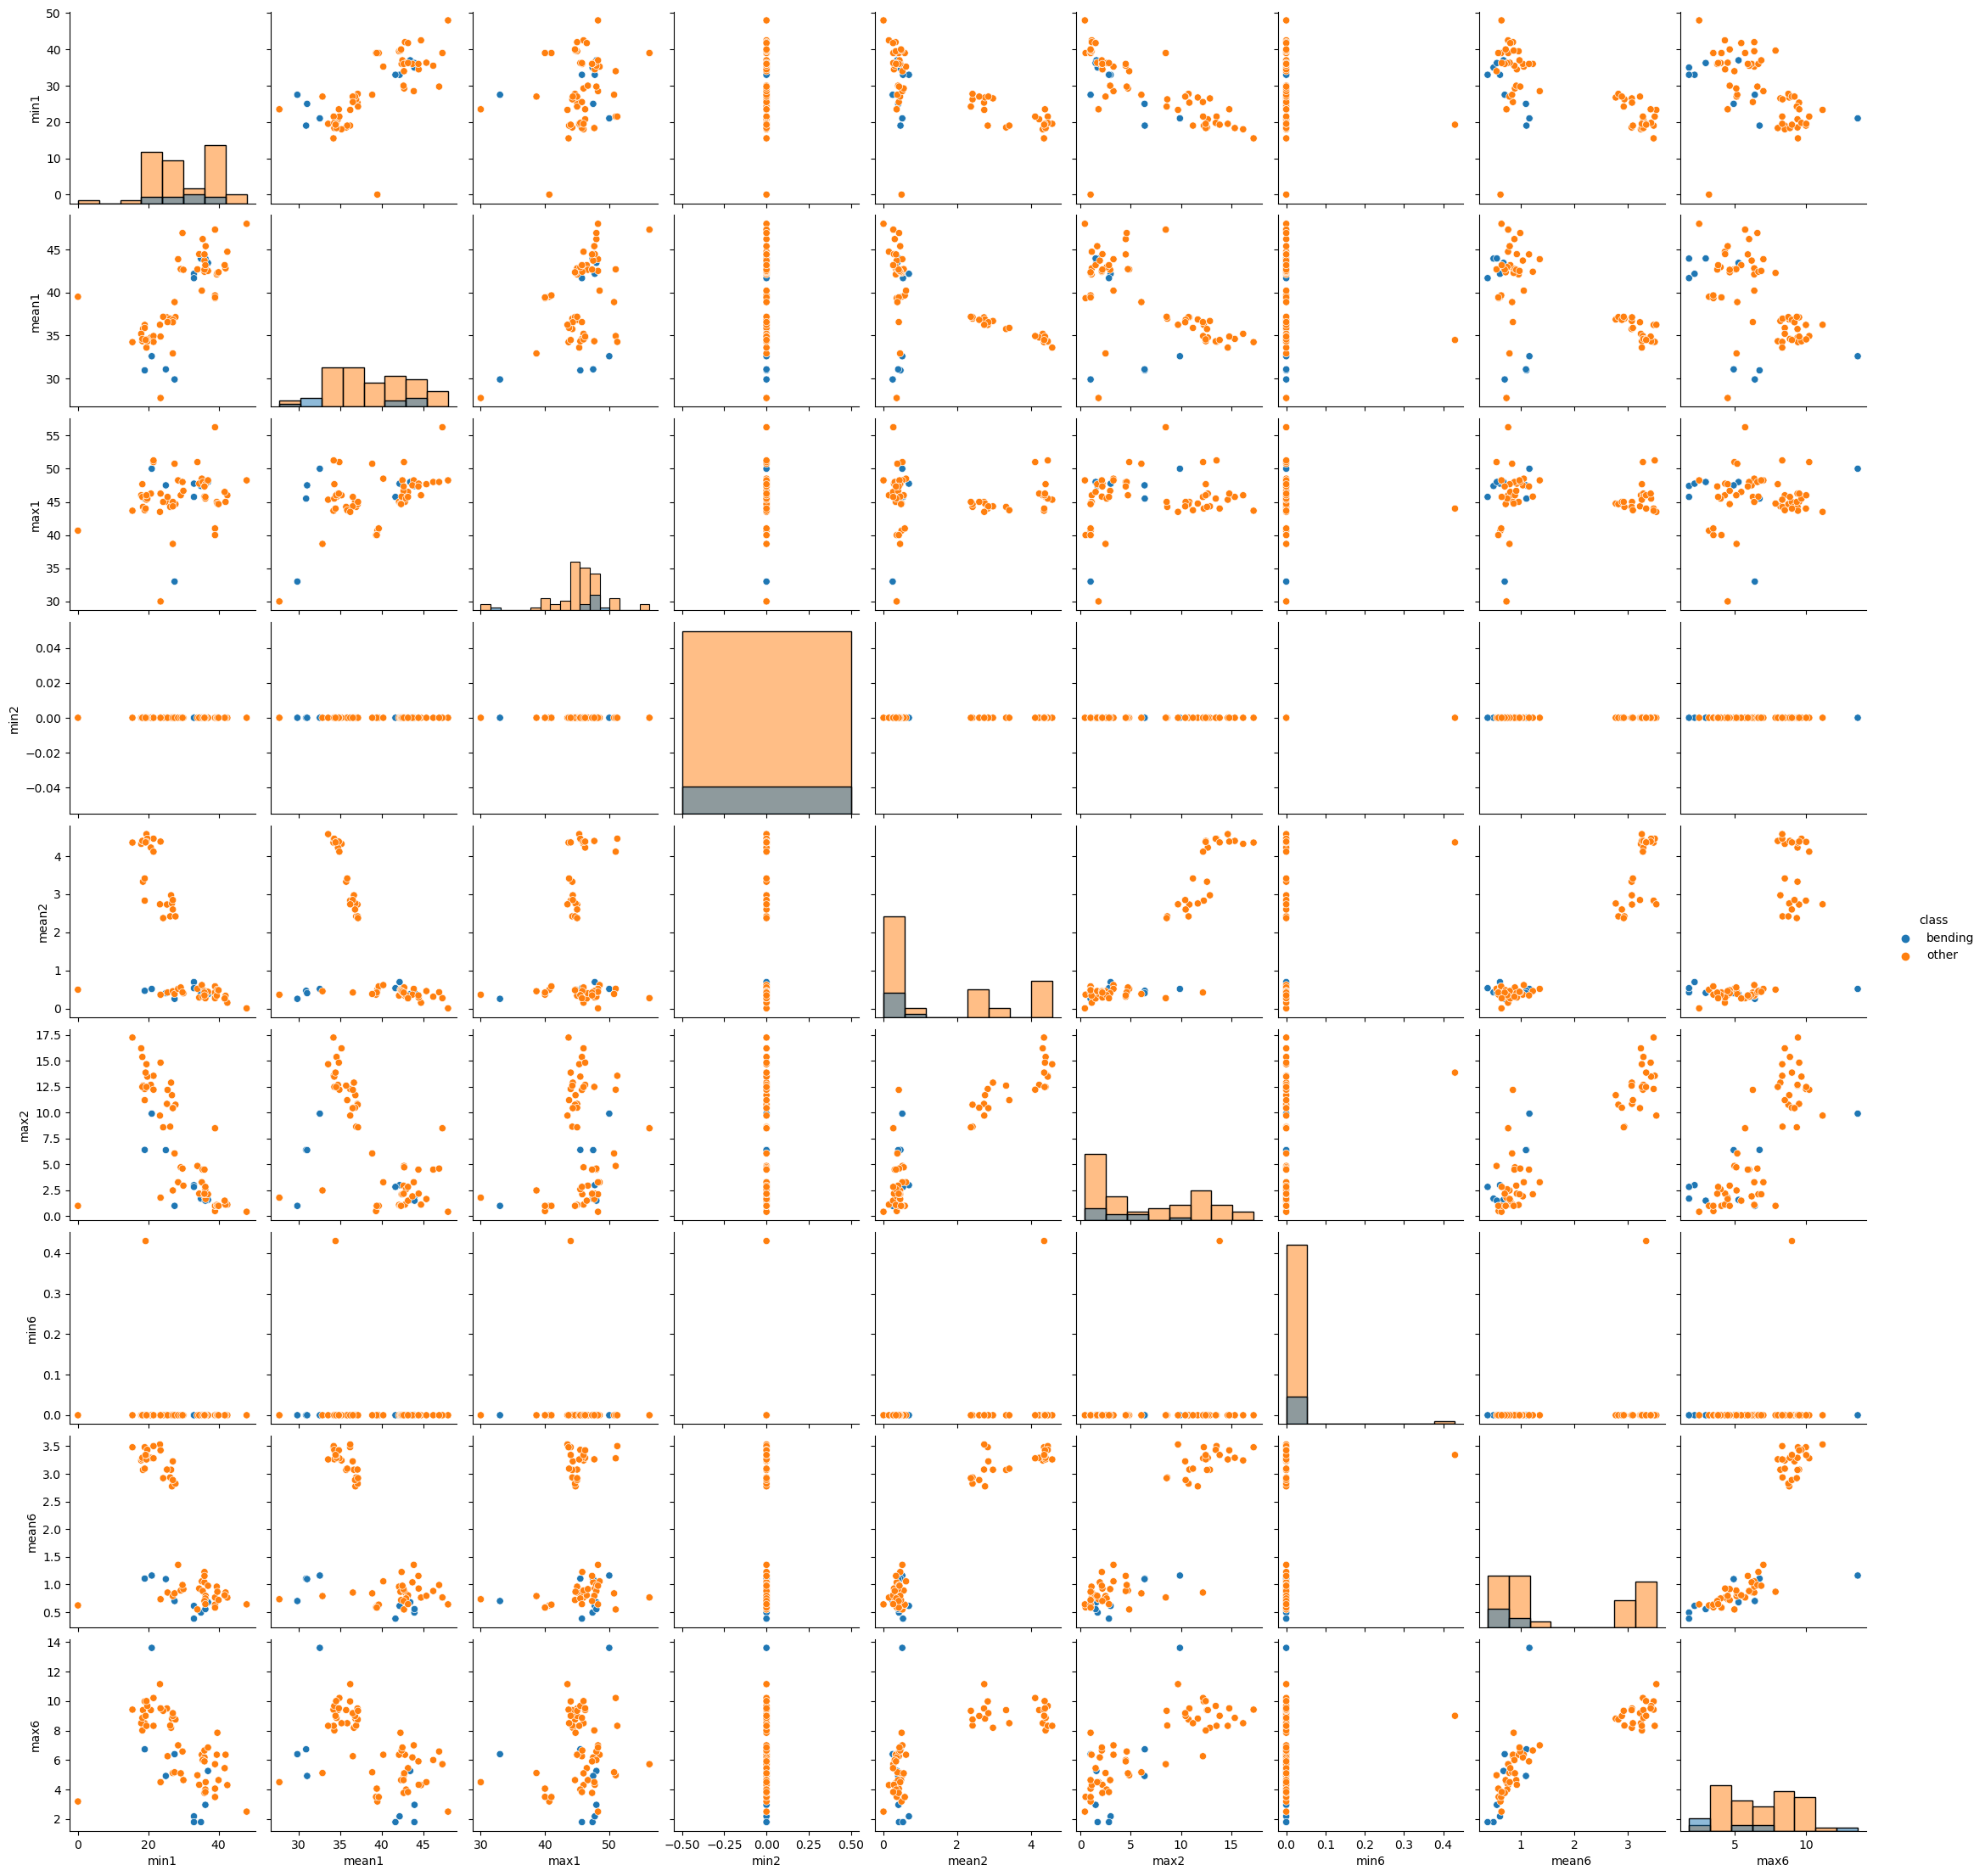

In [22]:
# Scatter plots

plot_features = [
    "min1", "mean1", "max1",
    "min2", "mean2", "max2",
    "min6", "mean6", "max6"
]

sns.pairplot(
    plot_df,
    vars=plot_features,
    hue="class",
    diag_kind="hist"
)

plt.show()

The scatter plots show some separation between the bending and other activities, although the two classes are not perfectly separated.

In particular, the mean and maximum features from time series 2 and 6 appear to provide useful discrimination, since many bending observations are concentrated in lower-value regions. In contrast, the minimum values of time series 2 and 6 are close to zero for most observations and therefore appear to provide relatively little discriminatory information.

Overall, the plots suggest that combinations of the selected features may be useful for distinguishing bending activities from the other activities, but no single pair of features appears to completely separate the two classes.

#### ii. Splitted Plots

Each of the six time series in every training instance is divided into two approximately equal-length segments. The minimum, mean, and maximum are then extracted separately from both segments of time series 1, 2, and 6.

Thus, each original selected time series contributes six features: three features from the first segment and three from the second segment.

In [23]:
def extract_two_segment_features(df):
    features = {}

    selected_series = {
        1: "avg_rss12",
        2: "var_rss12",
        6: "var_rss23"
    }

    for series_num, column in selected_series.items():
        segments = np.array_split(df[column].to_numpy(), 2)

        for segment_num, segment in enumerate(segments, start=1):
            features[f"min{series_num}_seg{segment_num}"] = np.min(segment)
            features[f"mean{series_num}_seg{segment_num}"] = np.mean(segment)
            features[f"max{series_num}_seg{segment_num}"] = np.max(segment)

    return features

In [24]:
split_plot_rows = []

for activity, file_path in train_files:
    df = read_arem_file(file_path)

    features = extract_two_segment_features(df)

    features["activity"] = activity
    features["class"] = (
        "bending"
        if activity in ["bending1", "bending2"]
        else "other"
    )

    split_plot_rows.append(features)

split_plot_df = pd.DataFrame(split_plot_rows)

split_plot_df.head()

,min1_seg1,mean1_seg1,max1_seg1,min1_seg2,mean1_seg2,max1_seg2,min2_seg1,mean2_seg1,max2_seg1,min2_seg2,mean2_seg2,max2_seg2,min6_seg1,mean6_seg1,max6_seg1,min6_seg2,mean6_seg2,max6_seg2,activity,class
0,36.50,44.057167,46.50,35.00,43.851833,47.40,0.0,0.381042,1.50,0.0,0.471458,1.70,0.0,0.598250,1.79,0.0,0.388333,1.50,bending1,bending
1,33.75,43.278875,47.75,33.00,41.080750,46.00,0.0,0.673292,3.00,0.0,0.718792,2.86,0.0,0.640958,1.53,0.0,0.586083,2.18,bending1,bending
2,33.00,41.621208,45.75,39.25,41.734917,43.67,0.0,0.623083,2.83,0.0,0.448875,1.12,0.0,0.419083,1.79,0.0,0.347500,1.50,bending1,bending
3,39.00,44.117042,48.00,37.00,42.792875,46.50,0.0,0.250042,1.30,0.0,0.506125,1.58,0.0,0.815417,5.26,0.0,0.543875,4.06,bending1,bending
4,36.67,43.486208,45.00,36.25,44.452042,48.00,0.0,0.378667,1.30,0.0,0.447583,1.50,0.0,0.524875,2.28,0.0,0.585750,2.96,bending1,bending


In [25]:
print("Shape:", split_plot_df.shape)
print()
print(split_plot_df["class"].value_counts())

Shape: (69, 20)

class
other      60
bending     9
Name: count, dtype: int64


To keep the scatter-plot matrices readable, the features from the two segments are displayed separately. Each plot contains the minimum, mean, and maximum features from time series 1, 2, and 6 for one segment.

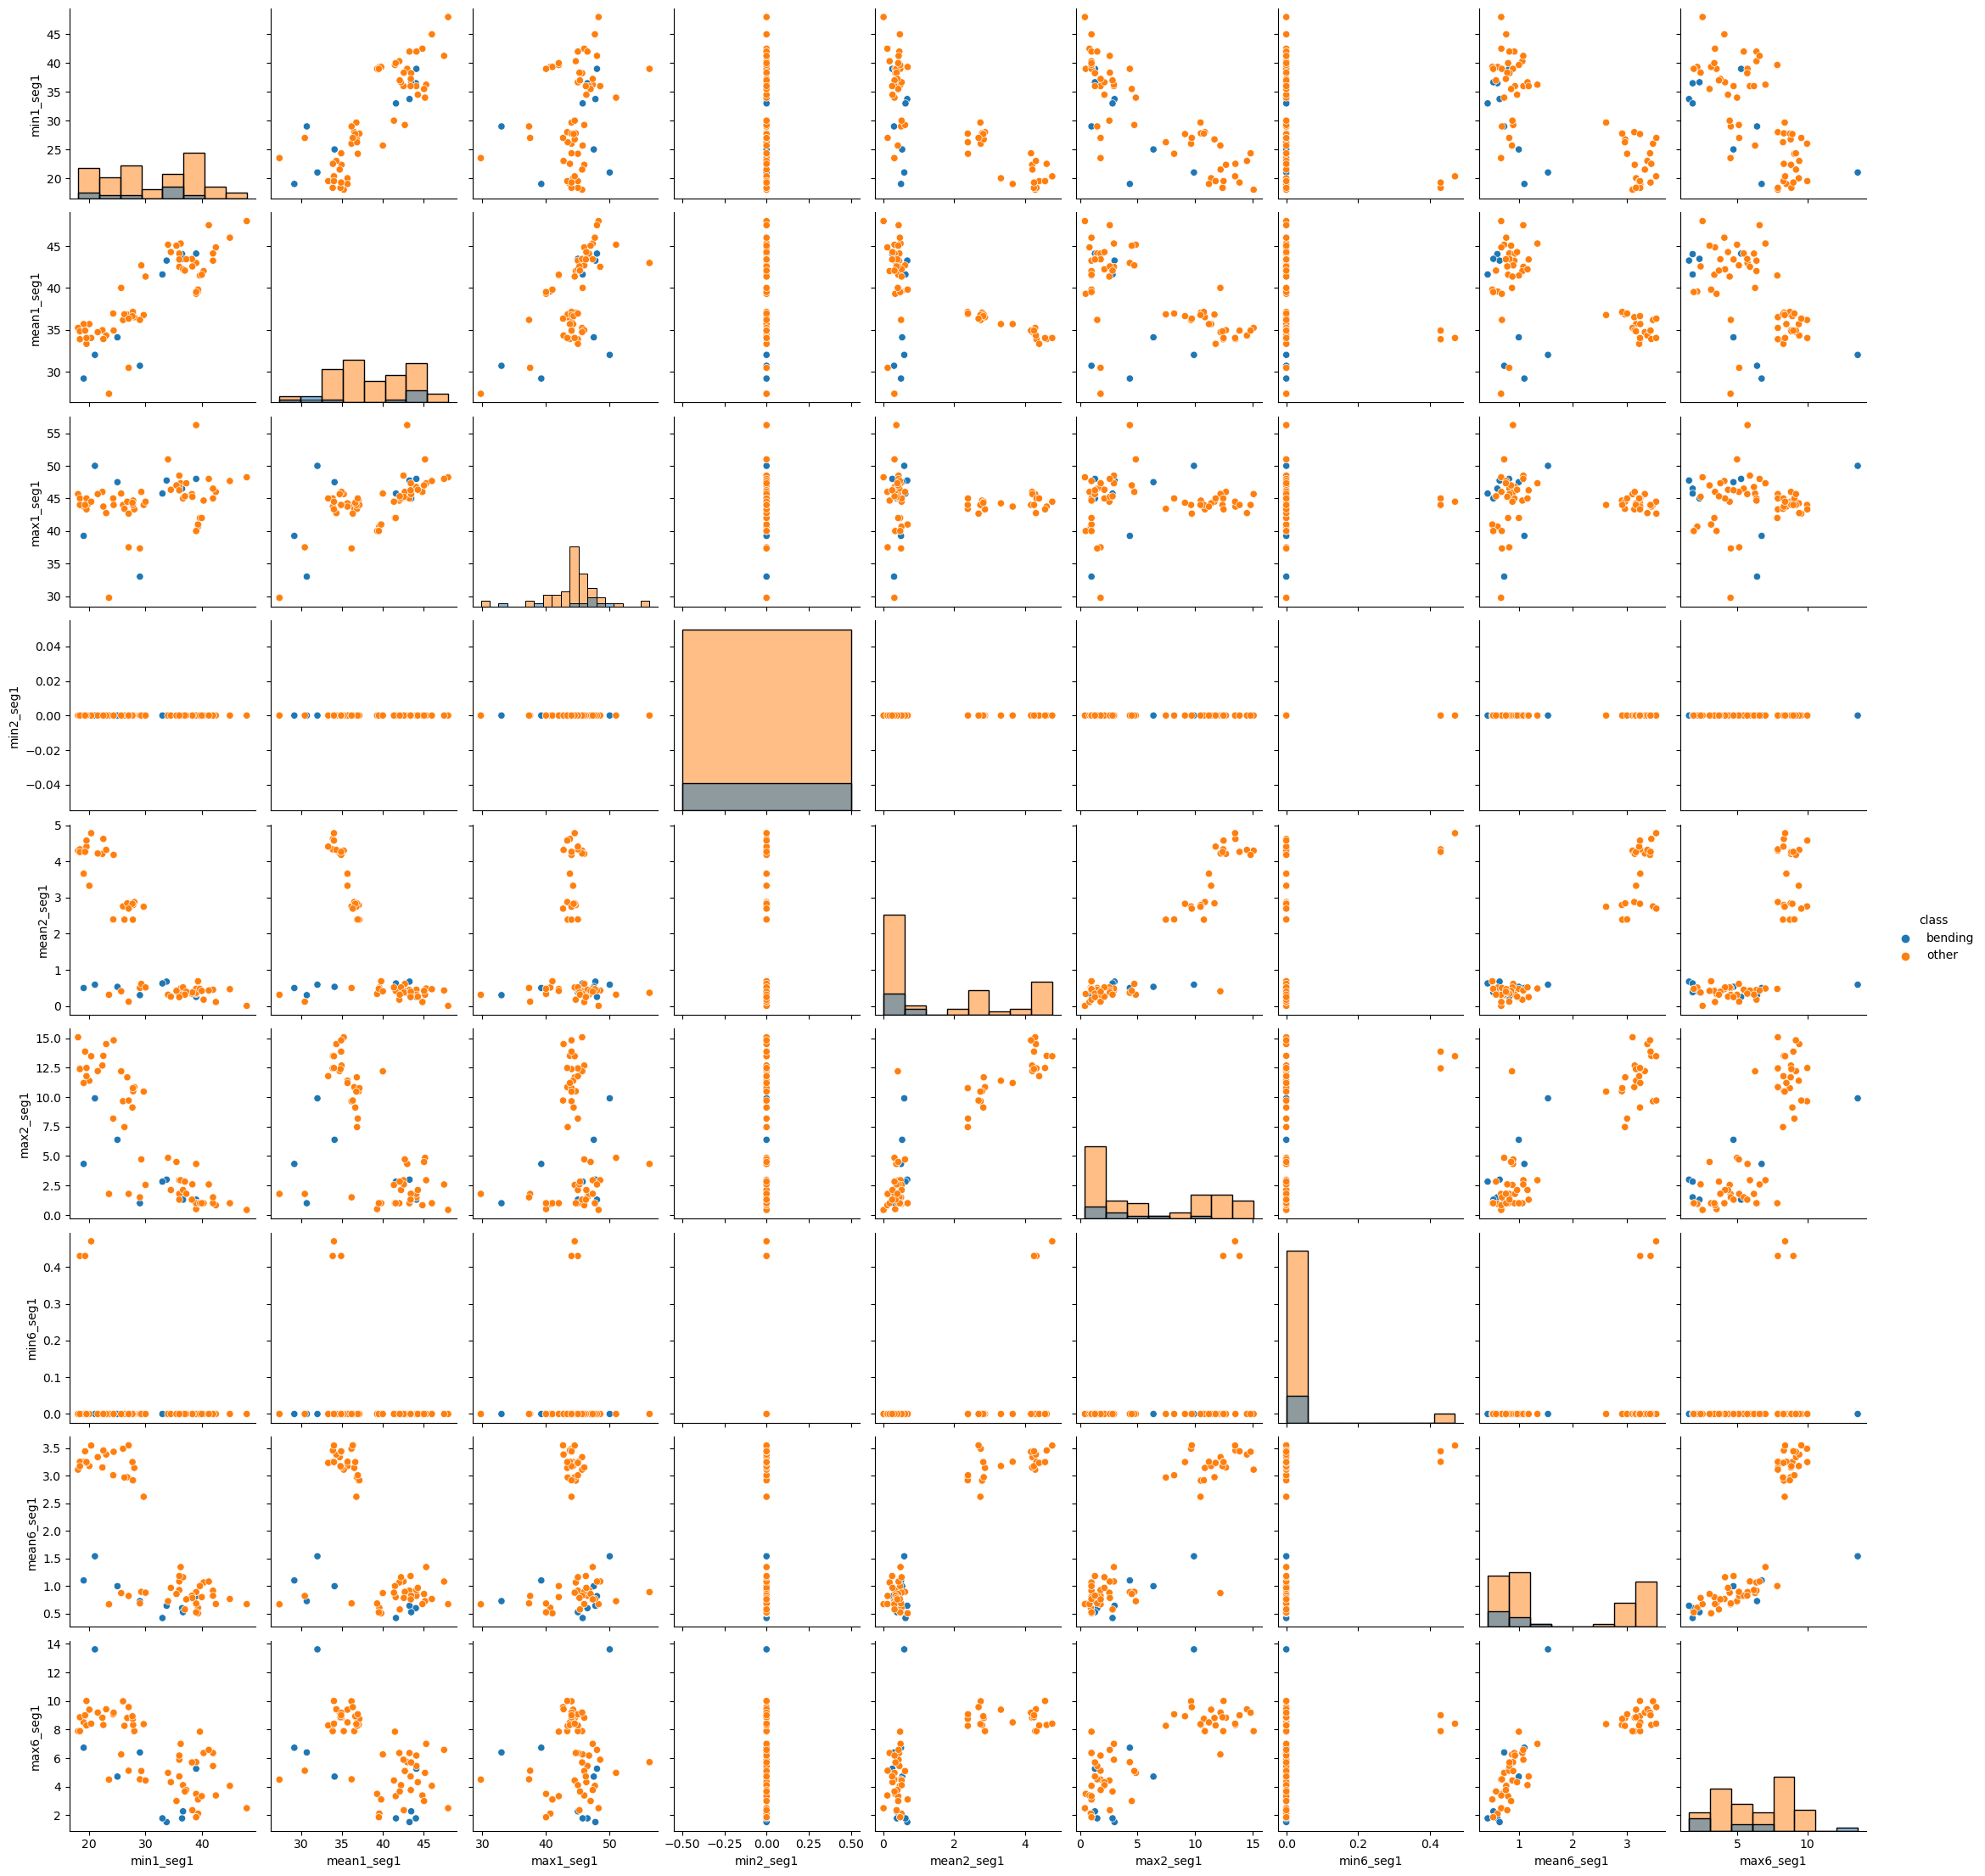

In [26]:
# First Segment

segment1_features = [
    "min1_seg1", "mean1_seg1", "max1_seg1",
    "min2_seg1", "mean2_seg1", "max2_seg1",
    "min6_seg1", "mean6_seg1", "max6_seg1"
]

sns.pairplot(
    split_plot_df,
    vars=segment1_features,
    hue="class",
    diag_kind="hist"
)

plt.show()

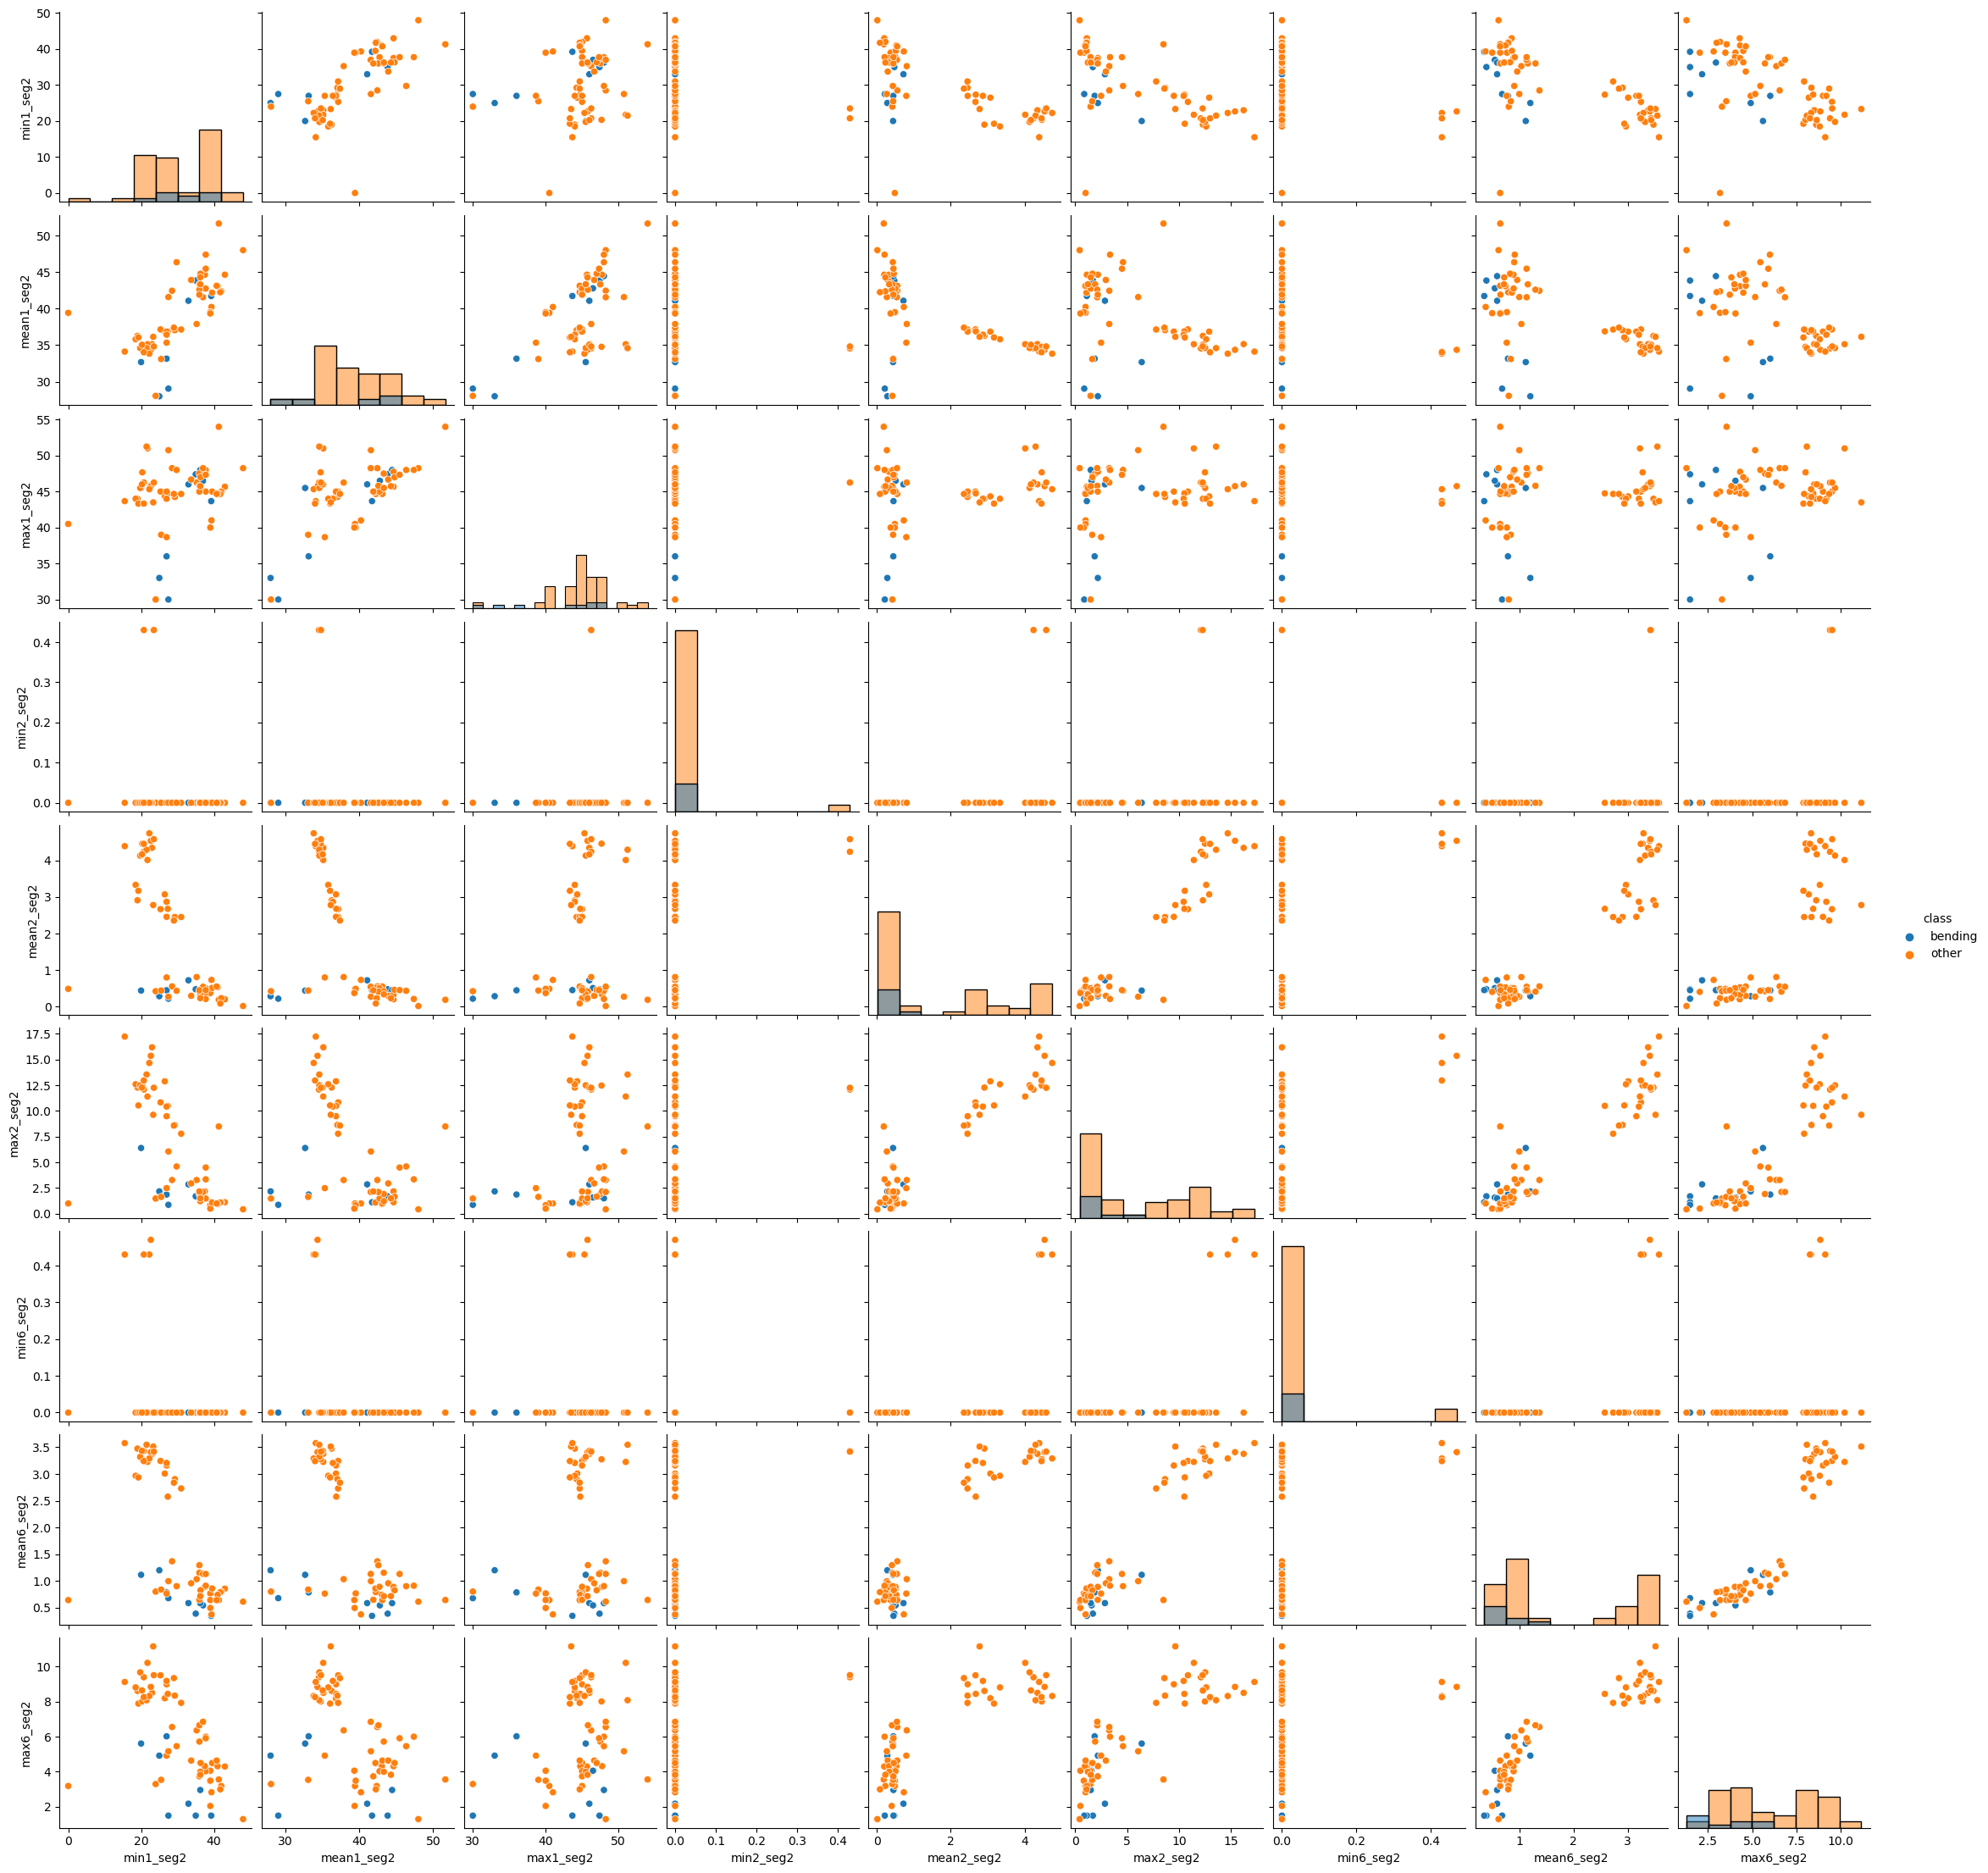

In [27]:
# Second Segment

segment2_features = [
    "min1_seg2", "mean1_seg2", "max1_seg2",
    "min2_seg2", "mean2_seg2", "max2_seg2",
    "min6_seg2", "mean6_seg2", "max6_seg2"
]

sns.pairplot(
    split_plot_df,
    vars=segment2_features,
    hue="class",
    diag_kind="hist"
)

plt.show()

The scatter plots obtained after dividing each time series into two segments show patterns that are generally similar to those observed before segmentation.

The mean and maximum features from time series 2 and 6 continue to provide some separation between the bending and other activities, whereas the minimum features from these time series remain concentrated near zero and appear less informative.

Although segmentation introduces some variation between the first and second halves of the time series, there is no considerable improvement in the visual separation of the two classes compared with the results in Part 2(a)i.

#### iii. Time Series Segments

For each value of $l \in \{1, 2, \ldots, 20\}$, every time series in each training instance is divided into $l$ approximately equal-length segments.

For each segment, the seven time-domain features used in Part 1 are extracted: minimum, maximum, mean, median, standard deviation, first quartile, and third quartile. Since each instance contains six time series, this produces $42l$ candidate features for each value of $l$.

A binary target is defined as 1 for the bending activities and 0 for all other activities.

In [28]:
def extract_segmented_features(df, l):
    features = {}

    time_series = [
        "avg_rss12",
        "var_rss12",
        "avg_rss13",
        "var_rss13",
        "avg_rss23",
        "var_rss23"
    ]

    for series_num, column in enumerate(time_series, start=1):
        segments = np.array_split(df[column].to_numpy(), l)

        for segment_num, segment in enumerate(segments, start=1):
            features[f"min{series_num}_seg{segment_num}"] = np.min(segment)
            features[f"max{series_num}_seg{segment_num}"] = np.max(segment)
            features[f"mean{series_num}_seg{segment_num}"] = np.mean(segment)
            features[f"median{series_num}_seg{segment_num}"] = np.median(segment)
            features[f"std{series_num}_seg{segment_num}"] = np.std(
                segment,
                ddof=1
            )
            features[f"1st_quart{series_num}_seg{segment_num}"] = np.percentile(
                segment,
                25
            )
            features[f"3rd_quart{series_num}_seg{segment_num}"] = np.percentile(
                segment,
                75
            )

    return features

In [29]:
def build_feature_matrix(file_list, l):
    rows = []
    labels = []

    for activity, file_path in file_list:
        df = read_arem_file(file_path)

        features = extract_segmented_features(df, l)
        rows.append(features)

        labels.append(
            1 if activity in ["bending1", "bending2"] else 0
        )

    X = pd.DataFrame(rows)
    y = pd.Series(labels, name="bending")

    return X, y

In [30]:
for l in [1, 2, 20]:
    X_l, y_l = build_feature_matrix(train_files, l)

    print(
        f"l={l}: X shape={X_l.shape}, "
        f"y shape={y_l.shape}"
    )

l=1: X shape=(69, 42), y shape=(69,)
l=2: X shape=(69, 84), y shape=(69,)
l=20: X shape=(69, 840), y shape=(69,)


##### Cross-Validation and Feature Selection

The number of candidate features increases with the number of segments $l$. Recursive Feature Elimination (RFE) is therefore used with logistic regression to select a subset of $p$ features.

Five-fold stratified cross-validation is used because the binary response is imbalanced, with substantially fewer bending instances than other activities. For each candidate pair $(l,p)$, feature selection is performed within each training fold rather than before cross-validation. This prevents information from the validation fold from influencing feature selection.

##### Correct and Incorrect Cross-Validation Procedures

The correct procedure is to perform feature selection separately within each training fold of cross-validation. The feature-selection algorithm must not have access to the validation fold when determining which features to retain. Using a pipeline ensures that scaling, RFE, and logistic regression are fitted using only the training portion of each fold.

An incorrect procedure would be to apply RFE to the entire training dataset first and then perform cross-validation using the already selected features. In that case, information from observations that later appear in validation folds would already have influenced feature selection. This would introduce
data leakage and could produce an overly optimistic estimate of cross-validation performance.

In [31]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [32]:
def make_rfe_pipeline(p):
    selector_model = LogisticRegression(
        penalty=None,
        solver="lbfgs",
        max_iter=2000
    )

    classifier = LogisticRegression(
        penalty=None,
        solver="lbfgs",
        max_iter=2000
    )

    return Pipeline([
        ("scaler", StandardScaler()),
        ("rfe", RFE(
            estimator=selector_model,
            n_features_to_select=p,
            step=0.1  # Remove 10% of the remaining features at each RFE step
        )),
        ("logistic", classifier)
    ])

In [33]:
cv_results = []

p_candidates = [1, 2, 3, 5, 10, 15, 20]

for l in range(1, 21):
    X_l, y_l = build_feature_matrix(train_files, l)

    # Display progress during the computationally expensive RFE search
    print(f"Processing l={l} ({X_l.shape[1]} features)...")

    for p in p_candidates:
        pipeline = make_rfe_pipeline(p)

        scores = cross_val_score(
            pipeline,
            X_l,
            y_l,
            cv=cv,
            scoring="accuracy",
            n_jobs=-1  # Use all available CPU cores for parallel CV
        )

        cv_results.append({
            "l": l,
            "p": p,
            "mean_cv_accuracy": scores.mean(),
            "std_cv_accuracy": scores.std()
        })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df.head()

Processing l=1 (42 features)...
Processing l=2 (84 features)...
Processing l=3 (126 features)...
Processing l=4 (168 features)...
Processing l=5 (210 features)...
Processing l=6 (252 features)...
Processing l=7 (294 features)...
Processing l=8 (336 features)...
Processing l=9 (378 features)...
Processing l=10 (420 features)...
Processing l=11 (462 features)...
Processing l=12 (504 features)...
Processing l=13 (546 features)...
Processing l=14 (588 features)...
Processing l=15 (630 features)...
Processing l=16 (672 features)...
Processing l=17 (714 features)...
Processing l=18 (756 features)...
Processing l=19 (798 features)...
Processing l=20 (840 features)...


,l,p,mean_cv_accuracy,std_cv_accuracy
0,1,1,0.913187,0.053203
1,1,2,0.942857,0.053452
2,1,3,0.942857,0.053452
3,1,5,0.928571,0.045175
4,1,10,0.957143,0.057143


In [34]:
best_result = (
    cv_results_df
    .sort_values(
        ["mean_cv_accuracy", "p", "l"],
        ascending=[False, True, True]
    )
    .iloc[0]
)

best_result

l                   19.000000
p                    3.000000
mean_cv_accuracy     0.971429
std_cv_accuracy      0.034993
Name: 128, dtype: float64

In [35]:
cv_results_df.sort_values(
    "mean_cv_accuracy",
    ascending=False
).head(10)

,l,p,mean_cv_accuracy,std_cv_accuracy
25,4,10,0.971429,0.034993
128,19,3,0.971429,0.034993
129,19,5,0.971429,0.034993
26,4,15,0.971429,0.034993
89,13,15,0.971429,0.034993
88,13,10,0.971429,0.034993
69,10,20,0.971429,0.034993
85,13,2,0.970330,0.036380
131,19,15,0.957143,0.057143
132,19,20,0.957143,0.057143


The highest mean 5-fold cross-validation accuracy was approximately **0.9714**. Several combinations of $l$ and $p$ achieved the same cross-validation accuracy.

Among the tied models and the tested candidate values of $p$, the model with the smallest number of selected features was preferred to obtain a more parsimonious classifier. Therefore, the selected model uses $l=19$ time-series segments and $p=3$ features.

The standard deviation of the cross-validation accuracy for this model was approximately **0.0350**.

#### iv. Confusion Matrix

In [36]:
best_l = int(best_result["l"])
best_p = int(best_result["p"])

print("Best l:", best_l)
print("Best p:", best_p)

Best l: 19
Best p: 3


In [37]:
X_train, y_train = build_feature_matrix(
    train_files,
    best_l
)

final_pipeline = make_rfe_pipeline(best_p)
final_pipeline.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('rfe',
                 RFE(estimator=LogisticRegression(max_iter=2000, penalty=None),
                     n_features_to_select=3, step=0.1)),
                ('logistic', LogisticRegression(max_iter=2000, penalty=None))])

In [38]:
selected_mask = final_pipeline.named_steps["rfe"].support_
selected_features = X_train.columns[selected_mask].tolist()

selected_features

['min5_seg3', '1st_quart5_seg3', 'max5_seg19']

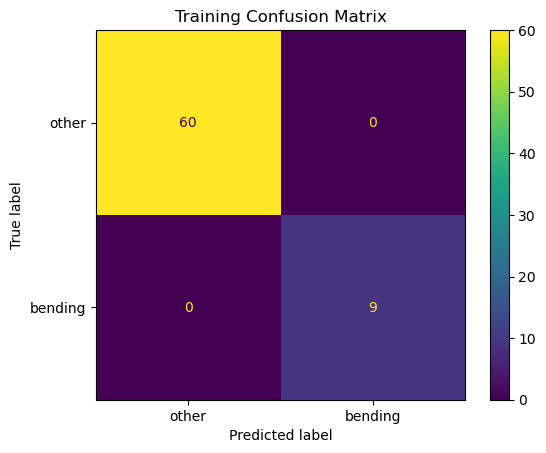

array([[60,  0],
       [ 0,  9]])

In [39]:
# Training confusion matrix

y_train_pred = final_pipeline.predict(X_train)

cm = confusion_matrix(y_train, y_train_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["other", "bending"]
).plot()

plt.title("Training Confusion Matrix")
plt.show()

cm

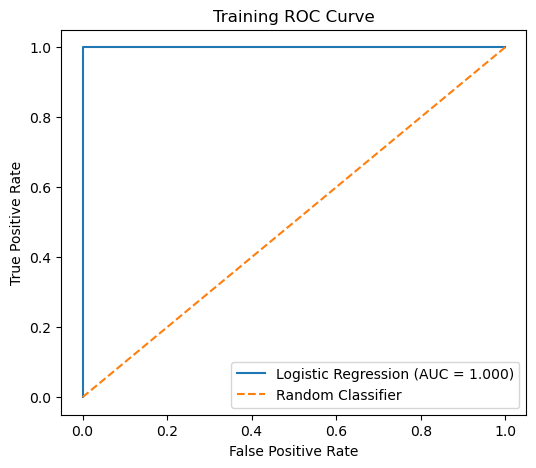

Training AUC: 1.0000


In [40]:
# ROC & AUC

y_train_prob = final_pipeline.predict_proba(X_train)[:, 1]

fpr, tpr, _ = roc_curve(y_train, y_train_prob)
train_auc = roc_auc_score(y_train, y_train_prob)

plt.figure(figsize=(6, 5))
plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {train_auc:.3f})"
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Training ROC Curve")
plt.legend()
plt.show()

print(f"Training AUC: {train_auc:.4f}")

In [41]:
# Coefficients & p-values

scaler = final_pipeline.named_steps["scaler"]

X_train_scaled = scaler.transform(X_train)

X_selected = X_train_scaled[:, selected_mask]

X_selected_sm = pd.DataFrame(
    X_selected,
    columns=selected_features
)

X_selected_sm = sm.add_constant(X_selected_sm)

In [42]:
# Coefficients of the fitted logistic regression classifier

final_logistic = final_pipeline.named_steps["logistic"]

coefficient_df = pd.DataFrame({
    "Feature": selected_features,
    "Coefficient": final_logistic.coef_[0]
})

print(f"Intercept: {final_logistic.intercept_[0]:.6f}")
display(coefficient_df)

Intercept: -56.200745


,Feature,Coefficient
0,min5_seg3,-1.581492
1,1st_quart5_seg3,57.570321
2,max5_seg19,21.872617


The coefficients reported above correspond to the standardized selected features used by the final logistic regression pipeline. The relatively large coefficient magnitudes are consistent with the strong separation observed in the training data.

In [43]:
# Attempt to estimate coefficients and p-values using unregularized logistic regression

with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)

    try:
        logit_model = sm.Logit(
            y_train.reset_index(drop=True),
            X_selected_sm
        )

        logit_result = logit_model.fit(disp=False)

        coef_pvalue_df = pd.DataFrame({
            "Coefficient": logit_result.params,
            "P-value": logit_result.pvalues
        })

        display(coef_pvalue_df)

    except Exception as e:
        print(
            "Unregularized logistic regression could not produce stable "
            "coefficient and p-value estimates."
        )
        print("Reason:", type(e).__name__, "-", e)

Unregularized logistic regression could not produce stable coefficient and p-value estimates.
Reason: LinAlgError - Singular matrix


The final classifier perfectly classified all 69 training instances, with 60 true negatives, 9 true positives, and no misclassified observations. The training ROC curve also produced an AUC of **1.000**.

An attempt was made to estimate the coefficients and p-values of an unregularized logistic regression model using the three selected features. However, maximum-likelihood estimation did not converge and ultimately failed because of a singular matrix. Therefore, finite and stable coefficient and p-value estimates could not be obtained using ordinary unregularized logistic regression.

Together with the perfect training classification and AUC, this numerical instability suggests complete or near-complete separation between the two classes. This issue is discussed further in Part 2(a)vi.

#### v. Test Classifier

The test instances are divided into the same number of segments selected using the training data, $l=19$. The features are extracted independently from the test set, and the classifier fitted on the training data is used without any further feature selection or model tuning.

The resulting test accuracy is compared with the mean cross-validation accuracy obtained from the training data.

In [44]:
X_test, y_test = build_feature_matrix(
    test_files,
    best_l
)

print("Test feature matrix shape:", X_test.shape)
print("Test target shape:", y_test.shape)

Test feature matrix shape: (19, 798)
Test target shape: (19,)


In [45]:
y_test_pred = final_pipeline.predict(X_test)
y_test_prob = final_pipeline.predict_proba(X_test)[:, 1]

test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Cross-Validation Accuracy: {best_result['mean_cv_accuracy']:.4f}")

Test Accuracy: 0.9474
Cross-Validation Accuracy: 0.9714


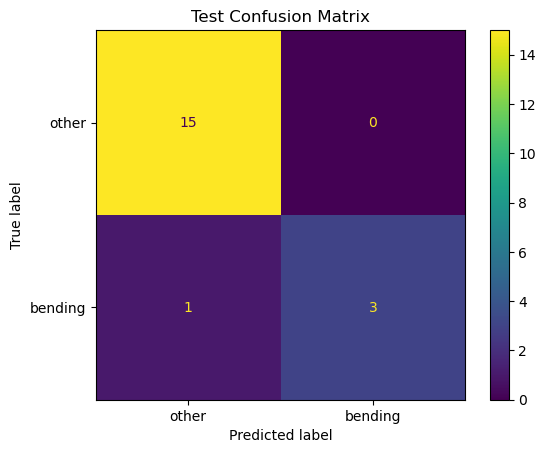

In [46]:
test_cm = confusion_matrix(y_test, y_test_pred)

ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=["other", "bending"]
).plot()

plt.title("Test Confusion Matrix")
plt.show()

In [47]:
test_cm

array([[15,  0],
       [ 1,  3]])

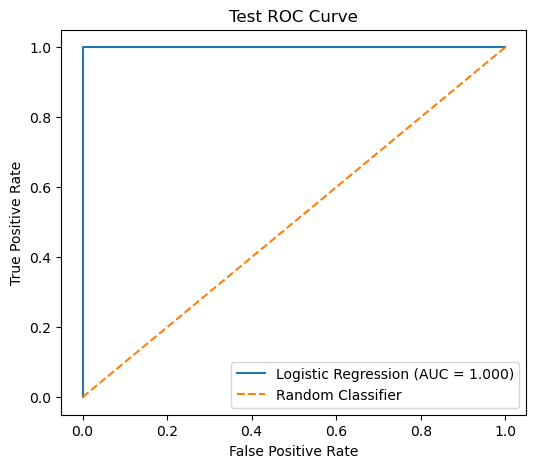

Test AUC: 1.0000


In [48]:
test_auc = roc_auc_score(y_test, y_test_prob)

fpr_test, tpr_test, _ = roc_curve(
    y_test,
    y_test_prob
)

plt.figure(figsize=(6, 5))

plt.plot(
    fpr_test,
    tpr_test,
    label=f"Logistic Regression (AUC = {test_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Test ROC Curve")
plt.legend()
plt.show()

print(f"Test AUC: {test_auc:.4f}")

The final classifier achieved a test accuracy of **0.9474**, correctly classifying 18 of the 19 test instances. This is slightly lower than the mean 5-fold cross-validation accuracy of **0.9714**, with a difference of approximately 0.024 (2.4 percentage points).

The test confusion matrix shows that all 15 other-activity instances were classified correctly, while 3 of the 4 bending instances were classified correctly. One bending instance was misclassified as an other activity.

The test AUC was **1.000**, indicating perfect ranking of the bending instances above the other instances by predicted probability. The AUC can still be 1.000 despite one classification error because the confusion matrix uses a fixed classification threshold, whereas the AUC evaluates ranking across all possible thresholds.

#### vi. Separation

The two classes appear to be completely or nearly completely separated in the training data. The final classifier correctly classified all 69 training instances and achieved a training AUC of **1.000**.

This strong separation also caused instability when estimating the parameters of the unregularized logistic regression model. Maximum-likelihood estimation failed to converge and resulted in a singular matrix, so finite and stable coefficient and p-value estimates could not be obtained.

Therefore, the results provide strong evidence that separation between the bending and other classes is causing instability in the logistic regression parameter estimates.

#### vii. Imbalance

The binary classes are imbalanced. In the training set, there are 60 other-activity instances and only 9 bending instances. The test set also contains more other-activity instances than bending instances.

To address this imbalance, case-control sampling is used to create a balanced training sample by retaining all bending instances and randomly sampling an equal number of other-activity instances. Because this sampling changes the class prevalence, the intercept of the fitted logistic regression model must be adjusted to account for the original population class proportions.

In [49]:
case_indices = y_train[y_train == 1].index
control_indices = y_train[y_train == 0].sample(
    n=len(case_indices),
    random_state=42
).index

case_control_indices = case_indices.union(control_indices)

X_cc = X_train.loc[case_control_indices]
y_cc = y_train.loc[case_control_indices]

print(y_cc.value_counts())

bending
1    9
0    9
Name: count, dtype: int64


In [50]:
cc_scaler = StandardScaler()

X_cc_selected = X_cc[selected_features]
X_cc_scaled = cc_scaler.fit_transform(X_cc_selected)

X_cc_scaled = pd.DataFrame(
    X_cc_scaled,
    columns=selected_features,
    index=X_cc_selected.index
)

In [51]:
cc_model = LogisticRegression(
    penalty=None,
    solver="lbfgs",
    max_iter=2000
)

cc_model.fit(X_cc_scaled, y_cc)

LogisticRegression(max_iter=2000, penalty=None)

In [52]:
print("Intercept:", cc_model.intercept_[0])

pd.DataFrame({
    "Feature": selected_features,
    "Coefficient": cc_model.coef_[0]
})

Intercept: 6.56640652375119


,Feature,Coefficient
0,min5_seg3,7.445782
1,1st_quart5_seg3,37.425806
2,max5_seg19,13.103976


In [53]:
original_prevalence = y_train.mean()
sample_prevalence = y_cc.mean()

intercept_adjustment = np.log(
    (original_prevalence / (1 - original_prevalence))
    /
    (sample_prevalence / (1 - sample_prevalence))
)

adjusted_intercept = (
    cc_model.intercept_[0]
    + intercept_adjustment
)

print("Original prevalence:", original_prevalence)
print("Case-control prevalence:", sample_prevalence)
print("Original intercept:", cc_model.intercept_[0])
print("Intercept adjustment:", intercept_adjustment)
print("Adjusted intercept:", adjusted_intercept)

Original prevalence: 0.13043478260869565
Case-control prevalence: 0.5
Original intercept: 6.56640652375119
Intercept adjustment: -1.8971199848858813
Adjusted intercept: 4.669286538865308


In [54]:
X_test_cc_scaled = cc_scaler.transform(
    X_test[selected_features]
)

In [55]:
test_log_odds_cc = (
    adjusted_intercept
    + X_test_cc_scaled @ cc_model.coef_[0]
)

y_test_prob_cc = 1 / (
    1 + np.exp(-test_log_odds_cc)
)

y_test_pred_cc = (
    y_test_prob_cc >= 0.5
).astype(int)

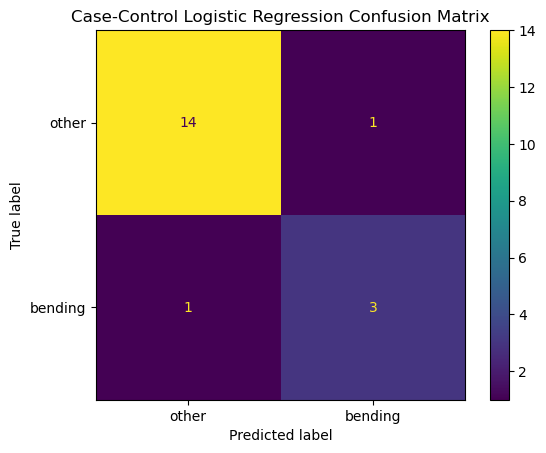

array([[14,  1],
       [ 1,  3]])

In [56]:
cc_cm = confusion_matrix(
    y_test,
    y_test_pred_cc
)

ConfusionMatrixDisplay(
    confusion_matrix=cc_cm,
    display_labels=["other", "bending"]
).plot()

plt.title("Case-Control Logistic Regression Confusion Matrix")
plt.show()

cc_cm

In [57]:
cc_accuracy = (y_test_pred_cc == y_test).mean()

print(f"Case-Control Test Accuracy: {cc_accuracy:.4f}")

Case-Control Test Accuracy: 0.8947


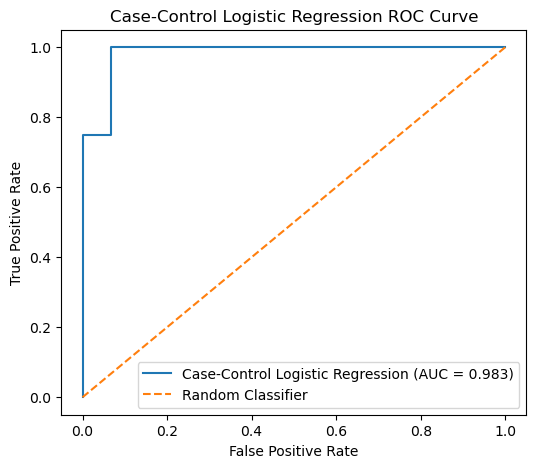

Case-Control Test AUC: 0.9833


In [58]:
cc_auc = roc_auc_score(
    y_test,
    y_test_prob_cc
)

fpr_cc, tpr_cc, _ = roc_curve(
    y_test,
    y_test_prob_cc
)

plt.figure(figsize=(6, 5))

plt.plot(
    fpr_cc,
    tpr_cc,
    label=f"Case-Control Logistic Regression (AUC = {cc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Case-Control Logistic Regression ROC Curve")
plt.legend()
plt.show()

print(f"Case-Control Test AUC: {cc_auc:.4f}")

The original training data are substantially imbalanced, with 60 other-activity instances and only 9 bending instances. Case-control sampling was therefore used to create a balanced training sample containing 9 observations from each class.

Because the balanced sample changes the prevalence of the bending class from approximately **0.1304** to **0.5000**, the fitted intercept was adjusted to reflect the original class prevalence. The intercept correction was approximately **-1.8971**, changing the fitted intercept from **6.5664** to **4.6693**.

On the test set, the adjusted case-control model correctly classified 17 of the 19 instances, corresponding to an accuracy of approximately **0.8947**. The confusion matrix contained 14 true negatives, 3 true positives, 1 false positive, and 1 false negative.

The model achieved a test AUC of **0.9833**, indicating very strong discrimination between bending and other activities. However, its test accuracy and AUC were slightly lower than those of the original classifier. Thus, although case-control sampling addresses the class imbalance, it did not improve predictive performance for this particular train-test split.


### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

For L1-penalized logistic regression, the number of time-series segments $l$ and the regularization strength are selected using 5-fold stratified cross-validation.

For each $l \in \{1, 2, \ldots, 20\}$, the same segmented time-domain features used in Part 2(a)iii are extracted. The features are standardized within each cross-validation fold, and L1-penalized logistic regression is fitted using the `liblinear` solver.

The parameter $C$, which is the inverse of the regularization strength, is selected by cross-validation. Smaller values of $C$ correspond to stronger L1 regularization and therefore generally produce sparser models.

In [59]:
def make_l1_pipeline():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(
            penalty="l1",
            solver="liblinear",
            max_iter=5000
        ))
    ])

In [60]:
C_candidates = np.logspace(-4, 4, 20)

C_candidates

array([1.00000000e-04, 2.63665090e-04, 6.95192796e-04, 1.83298071e-03,
       4.83293024e-03, 1.27427499e-02, 3.35981829e-02, 8.85866790e-02,
       2.33572147e-01, 6.15848211e-01, 1.62377674e+00, 4.28133240e+00,
       1.12883789e+01, 2.97635144e+01, 7.84759970e+01, 2.06913808e+02,
       5.45559478e+02, 1.43844989e+03, 3.79269019e+03, 1.00000000e+04])

In [61]:
l1_results = []

for l in range(1, 21):
    X_l, y_l = build_feature_matrix(train_files, l)

    print(f"Processing l={l} ({X_l.shape[1]} features)...")

    pipeline = make_l1_pipeline()

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid={
            "logistic__C": C_candidates
        },
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    grid_search.fit(X_l, y_l)

    l1_results.append({
        "l": l,
        "best_C": grid_search.best_params_["logistic__C"],
        "mean_cv_accuracy": grid_search.best_score_,
        "std_cv_accuracy": grid_search.cv_results_[
            "std_test_score"
        ][grid_search.best_index_]
    })

l1_results_df = pd.DataFrame(l1_results)

l1_results_df

Processing l=1 (42 features)...
Processing l=2 (84 features)...
Processing l=3 (126 features)...
Processing l=4 (168 features)...
Processing l=5 (210 features)...
Processing l=6 (252 features)...
Processing l=7 (294 features)...
Processing l=8 (336 features)...
Processing l=9 (378 features)...
Processing l=10 (420 features)...
Processing l=11 (462 features)...
Processing l=12 (504 features)...
Processing l=13 (546 features)...
Processing l=14 (588 features)...
Processing l=15 (630 features)...
Processing l=16 (672 features)...
Processing l=17 (714 features)...
Processing l=18 (756 features)...
Processing l=19 (798 features)...
Processing l=20 (840 features)...


,l,best_C,mean_cv_accuracy,std_cv_accuracy
0,1,3792.690191,0.971429,0.034993
1,2,0.615848,0.957143,0.057143
2,3,0.233572,0.971429,0.034993
3,4,0.615848,0.957143,0.034993
4,5,4.281332,0.941758,0.029199
5,6,1.623777,0.957143,0.034993
6,7,0.615848,0.927473,0.045229
7,8,545.559478,0.942857,0.069985
8,9,0.615848,0.927473,0.045229
9,10,78.475997,0.971429,0.034993


In [62]:
best_l1_result = (
    l1_results_df
    .sort_values(
        ["mean_cv_accuracy", "l"],
        ascending=[False, True]
    )
    .iloc[0]
)

best_l1_result

l                   19.000000
best_C               0.615848
mean_cv_accuracy     0.985714
std_cv_accuracy      0.028571
Name: 18, dtype: float64

In [63]:
l1_results_df.sort_values(
    "mean_cv_accuracy",
    ascending=False
).head(10)

,l,best_C,mean_cv_accuracy,std_cv_accuracy
18,19,0.615848,0.985714,0.028571
0,1,3792.690191,0.971429,0.034993
9,10,78.475997,0.971429,0.034993
17,18,0.615848,0.971429,0.034993
16,17,206.913808,0.971429,0.034993
12,13,0.615848,0.971429,0.034993
11,12,0.615848,0.971429,0.034993
10,11,1.623777,0.971429,0.034993
2,3,0.233572,0.971429,0.034993
19,20,11.288379,0.971429,0.034993


In [64]:
best_l_l1 = int(best_l1_result["l"])
best_C_l1 = float(best_l1_result["best_C"])

print("Best l:", best_l_l1)
print("Best C:", best_C_l1)
print(
    "Best CV Accuracy:",
    f"{best_l1_result['mean_cv_accuracy']:.4f}"
)

Best l: 19
Best C: 0.615848211066026
Best CV Accuracy: 0.9857


In [65]:
X_train_l1, y_train_l1 = build_feature_matrix(
    train_files,
    best_l_l1
)

In [66]:
final_l1_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        penalty="l1",
        solver="liblinear",
        C=best_C_l1,
        max_iter=5000
    ))
])

final_l1_pipeline.fit(
    X_train_l1,
    y_train_l1
)

Pipeline(steps=[('scaler', StandardScaler()),
                ('logistic',
                 LogisticRegression(C=0.615848211066026, max_iter=5000,
                                    penalty='l1', solver='liblinear'))])

In [67]:
l1_coefficients = final_l1_pipeline.named_steps[
    "logistic"
].coef_[0]

nonzero_mask = l1_coefficients != 0

selected_l1_features = X_train_l1.columns[
    nonzero_mask
].tolist()

print(
    "Number of selected features:",
    len(selected_l1_features)
)

selected_l1_features

Number of selected features: 6


['max1_seg11',
 'min5_seg2',
 '1st_quart5_seg3',
 'min5_seg17',
 'std6_seg15',
 'max6_seg18']

In [68]:
l1_coef_df = pd.DataFrame({
    "Feature": X_train_l1.columns,
    "Coefficient": l1_coefficients
})

l1_coef_df = (
    l1_coef_df[l1_coef_df["Coefficient"] != 0]
    .sort_values(
        "Coefficient",
        key=abs,
        ascending=False
    )
)

l1_coef_df

,Feature,Coefficient
551,1st_quart5_seg3,1.775009
644,min5_seg17,0.465261
71,max1_seg11,-0.454040
785,max6_seg18,-0.171091
767,std6_seg15,-0.151626
539,min5_seg2,0.118695


The best L1-penalized logistic regression model was obtained with $l=19$ time-series segments and $C \approx 0.6158$. Its mean 5-fold cross-validation accuracy was approximately **0.9857**, with a standard deviation of approximately **0.0286**.

After fitting the selected model to the full training set, the L1 penalty retained 6 features with nonzero coefficients out of the 798 candidate features. This demonstrates the feature-selection effect of L1 regularization, which automatically shrinks many coefficients exactly to zero.

The selected features were:

- `max1_seg11`
- `min5_seg2`
- `1st_quart5_seg3`
- `min5_seg17`
- `std6_seg15`
- `max6_seg18`

#### ii. Comparison

The L1-penalized model is evaluated on the test set using the same value of $l=19$ selected by cross-validation. No additional model tuning is performed using the test data.

Its cross-validation and test performance are then compared with the RFE-based logistic regression model from Part 2(a).

In [69]:
X_test_l1, y_test_l1 = build_feature_matrix(
    test_files,
    best_l_l1
)

print("Test feature matrix shape:", X_test_l1.shape)

Test feature matrix shape: (19, 798)


In [70]:
y_test_pred_l1 = final_l1_pipeline.predict(X_test_l1)
y_test_prob_l1 = final_l1_pipeline.predict_proba(X_test_l1)[:, 1]

l1_test_accuracy = (
    y_test_pred_l1 == y_test_l1
).mean()

l1_test_auc = roc_auc_score(
    y_test_l1,
    y_test_prob_l1
)

print(
    f"L1 CV Accuracy: "
    f"{best_l1_result['mean_cv_accuracy']:.4f}"
)

print(
    f"L1 Test Accuracy: "
    f"{l1_test_accuracy:.4f}"
)

print(
    f"L1 Test AUC: "
    f"{l1_test_auc:.4f}"
)

L1 CV Accuracy: 0.9857
L1 Test Accuracy: 0.9474
L1 Test AUC: 0.9833


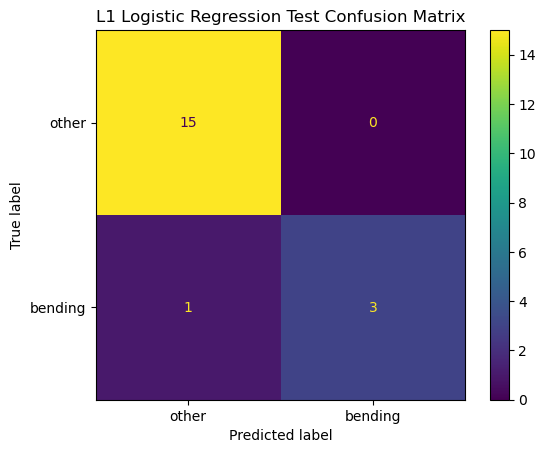

array([[15,  0],
       [ 1,  3]])

In [71]:
l1_test_cm = confusion_matrix(
    y_test_l1,
    y_test_pred_l1
)

ConfusionMatrixDisplay(
    confusion_matrix=l1_test_cm,
    display_labels=["other", "bending"]
).plot()

plt.title("L1 Logistic Regression Test Confusion Matrix")
plt.show()

l1_test_cm

In [72]:
comparison_df = pd.DataFrame({
    "Method": [
        "RFE + Logistic Regression",
        "L1 Logistic Regression"
    ],
    "CV Accuracy": [
        best_result["mean_cv_accuracy"],
        best_l1_result["mean_cv_accuracy"]
    ],
    "Test Accuracy": [
        test_accuracy,
        l1_test_accuracy
    ],
    "Test AUC": [
        test_auc,
        l1_test_auc
    ]
})

comparison_df

,Method,CV Accuracy,Test Accuracy,Test AUC
0,RFE + Logistic Regression,0.971429,0.947368,1.000000
1,L1 Logistic Regression,0.985714,0.947368,0.983333


The L1-penalized logistic regression achieved a higher mean cross-validation accuracy than the RFE-based logistic regression, with **0.9857** compared with **0.9714**.

However, both methods achieved the same test accuracy of **0.9474**. The RFE-based model achieved a test AUC of **1.0000**, while the L1-penalized model achieved a slightly lower test AUC of **0.9833**.

Therefore, the two methods have very similar predictive performance on the test set. Although the L1 model performed slightly better during cross-validation, this advantage did not translate into higher test accuracy.

The L1-penalized approach is easier to implement because feature selection and model fitting are performed simultaneously through regularization. In contrast, the RFE-based approach requires a separate feature-selection procedure and additional tuning of the number of selected features. In this dataset, the unregularized logistic regression used in the RFE-based approach also exhibited instability because of strong class separation.

Overall, the L1-penalized logistic regression provides a simpler and more stable modeling procedure while achieving test performance comparable to the RFE-based logistic regression.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

The activity labels are now treated as seven separate classes: `bending1`, `bending2`, `cycling`, `lying`, `sitting`, `standing`, and `walking`.

For each number of time-series segments $l \in \{1, 2, \ldots, 20\}$, the same time-domain features are extracted from each segment. The features are standardized within each cross-validation fold, and an L1-penalized multinomial logistic regression model is fitted.

The number of segments $l$ and the inverse regularization strength $C$ are selected using stratified cross-validation based only on the training data.

In [73]:
def build_multiclass_feature_matrix(file_list, l):
    feature_rows = []
    labels = []

    for activity, file_path in file_list:
        df = read_arem_file(file_path)

        features = extract_segmented_features(df, l)

        feature_rows.append(features)
        labels.append(activity)

    X = pd.DataFrame(feature_rows)
    y = pd.Series(labels, name="activity")

    return X, y

In [74]:
X_multi_1, y_multi_1 = build_multiclass_feature_matrix(
    train_files,
    1
)

print("X shape:", X_multi_1.shape)
print("y shape:", y_multi_1.shape)
print()
print(y_multi_1.value_counts())

X shape: (69, 42)
y shape: (69,)

activity
cycling     12
lying       12
sitting     12
standing    12
walking     12
bending1     5
bending2     4
Name: count, dtype: int64


Because the smallest training class (`bending2`) contains only four instances, 4-fold stratified cross-validation is used so that every fold can contain observations from each activity class.

In [75]:
cv_multi = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

In [76]:
def make_multiclass_l1_pipeline():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(
            penalty="l1",
            solver="saga",
            max_iter=10000,
            random_state=42
        ))
    ])

In [77]:
multiclass_results = []

for l in range(1, 21):
    X_l, y_l = build_multiclass_feature_matrix(
        train_files,
        l
    )

    print(f"Processing l={l} ({X_l.shape[1]} features)...")

    pipeline = make_multiclass_l1_pipeline()

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid={
            "logistic__C": C_candidates
        },
        cv=cv_multi,
        scoring="accuracy",
        n_jobs=-1
    )

    grid_search.fit(X_l, y_l)

    multiclass_results.append({
        "l": l,
        "best_C": grid_search.best_params_["logistic__C"],
        "mean_cv_accuracy": grid_search.best_score_,
        "std_cv_accuracy": grid_search.cv_results_[
            "std_test_score"
        ][grid_search.best_index_]
    })

multiclass_results_df = pd.DataFrame(
    multiclass_results
)

multiclass_results_df

Processing l=1 (42 features)...
Processing l=2 (84 features)...
Processing l=3 (126 features)...
Processing l=4 (168 features)...
Processing l=5 (210 features)...
Processing l=6 (252 features)...
Processing l=7 (294 features)...
Processing l=8 (336 features)...
Processing l=9 (378 features)...
Processing l=10 (420 features)...
Processing l=11 (462 features)...
Processing l=12 (504 features)...
Processing l=13 (546 features)...
Processing l=14 (588 features)...
Processing l=15 (630 features)...
Processing l=16 (672 features)...
Processing l=17 (714 features)...
Processing l=18 (756 features)...
Processing l=19 (798 features)...
Processing l=20 (840 features)...


,l,best_C,mean_cv_accuracy,std_cv_accuracy
0,1,1.623777,0.870098,0.085854
1,2,545.559478,0.927288,0.025977
2,3,1438.449888,0.898693,0.048362
3,4,206.913808,0.883987,0.041691
4,5,1438.449888,0.913399,0.027874
5,6,3792.690191,0.913399,0.027874
6,7,545.559478,0.883987,0.002830
7,8,206.913808,0.840686,0.048216
8,9,4.281332,0.883987,0.072099
9,10,545.559478,0.825980,0.072169


In [78]:
best_multiclass_result = (
    multiclass_results_df
    .sort_values(
        ["mean_cv_accuracy", "l"],
        ascending=[False, True]
    )
    .iloc[0]
)

best_multiclass_result

l                     2.000000
best_C              545.559478
mean_cv_accuracy      0.927288
std_cv_accuracy       0.025977
Name: 1, dtype: float64

In [79]:
multiclass_results_df.sort_values(
    "mean_cv_accuracy",
    ascending=False
).head(10)

,l,best_C,mean_cv_accuracy,std_cv_accuracy
1,2,545.559478,0.927288,0.025977
4,5,1438.449888,0.913399,0.027874
5,6,3792.690191,0.913399,0.027874
2,3,1438.449888,0.898693,0.048362
3,4,206.913808,0.883987,0.041691
6,7,545.559478,0.883987,0.002830
8,9,4.281332,0.883987,0.072099
0,1,1.623777,0.870098,0.085854
17,18,0.615848,0.855392,0.027183
11,12,206.913808,0.855392,0.049689


The best L1-penalized multinomial logistic regression model was obtained with $l=2$ time-series segments and $C \approx 545.5595$.

The model achieved a mean 4-fold cross-validation accuracy of approximately **0.9273**, with a standard deviation of approximately **0.0260**.

Among the candidate values considered, $l=2$ produced the highest cross-validation accuracy and was therefore selected for the final multiclass model.

In [80]:
best_l_multi = int(best_multiclass_result["l"])
best_C_multi = float(best_multiclass_result["best_C"])

print("Best l:", best_l_multi)
print("Best C:", best_C_multi)
print(
    "Best CV Accuracy:",
    f"{best_multiclass_result['mean_cv_accuracy']:.4f}"
)

Best l: 2
Best C: 545.5594781168514
Best CV Accuracy: 0.9273


In [81]:
X_train_multi, y_train_multi = build_multiclass_feature_matrix(
    train_files,
    best_l_multi
)

final_multiclass_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        penalty="l1",
        solver="saga",
        C=best_C_multi,
        max_iter=10000,
        random_state=42
    ))
])

final_multiclass_pipeline.fit(
    X_train_multi,
    y_train_multi
)

Pipeline(steps=[('scaler', StandardScaler()),
                ('logistic',
                 LogisticRegression(C=545.5594781168514, max_iter=10000,
                                    penalty='l1', random_state=42,
                                    solver='saga'))])

In [82]:
multi_coefficients = final_multiclass_pipeline.named_steps[
    "logistic"
].coef_

print("Coefficient matrix shape:", multi_coefficients.shape)
print(
    "Number of nonzero coefficients:",
    np.count_nonzero(multi_coefficients)
)
print(
    "Total number of coefficients:",
    multi_coefficients.size
)

Coefficient matrix shape: (7, 84)
Number of nonzero coefficients: 540
Total number of coefficients: 588


In [83]:
X_test_multi, y_test_multi = build_multiclass_feature_matrix(
    test_files,
    best_l_multi
)

print("Test feature matrix shape:", X_test_multi.shape)
print("Test target shape:", y_test_multi.shape)

Test feature matrix shape: (19, 84)
Test target shape: (19,)


In [84]:
y_test_pred_multi = final_multiclass_pipeline.predict(
    X_test_multi
)

multi_test_accuracy = (
    y_test_pred_multi == y_test_multi
).mean()

multi_test_error = 1 - multi_test_accuracy

print(
    f"Multiclass Test Accuracy: "
    f"{multi_test_accuracy:.4f}"
)

print(
    f"Multiclass Test Error: "
    f"{multi_test_error:.4f}"
)

Multiclass Test Accuracy: 0.8421
Multiclass Test Error: 0.1579


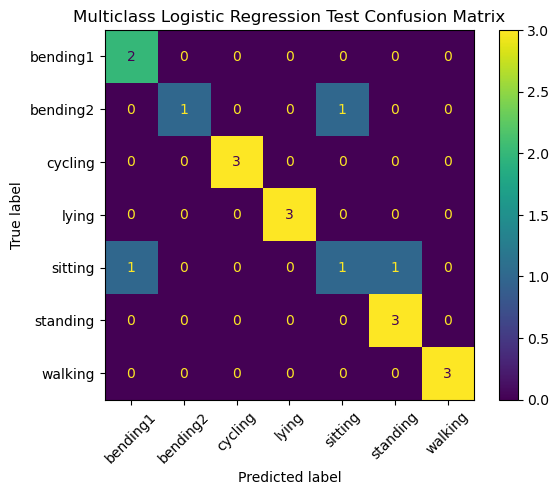

array([[2, 0, 0, 0, 0, 0, 0],
       [0, 1, 0, 0, 1, 0, 0],
       [0, 0, 3, 0, 0, 0, 0],
       [0, 0, 0, 3, 0, 0, 0],
       [1, 0, 0, 0, 1, 1, 0],
       [0, 0, 0, 0, 0, 3, 0],
       [0, 0, 0, 0, 0, 0, 3]])

In [85]:
multi_cm = confusion_matrix(
    y_test_multi,
    y_test_pred_multi,
    labels=final_multiclass_pipeline.named_steps[
        "logistic"
    ].classes_
)

ConfusionMatrixDisplay(
    confusion_matrix=multi_cm,
    display_labels=final_multiclass_pipeline.named_steps[
        "logistic"
    ].classes_
).plot(
    xticks_rotation=45
)

plt.title("Multiclass Logistic Regression Test Confusion Matrix")
plt.show()

multi_cm

In [86]:
y_test_prob_multi = final_multiclass_pipeline.predict_proba(
    X_test_multi
)

classes_multi = final_multiclass_pipeline.named_steps[
    "logistic"
].classes_

y_test_bin = label_binarize(
    y_test_multi,
    classes=classes_multi
)

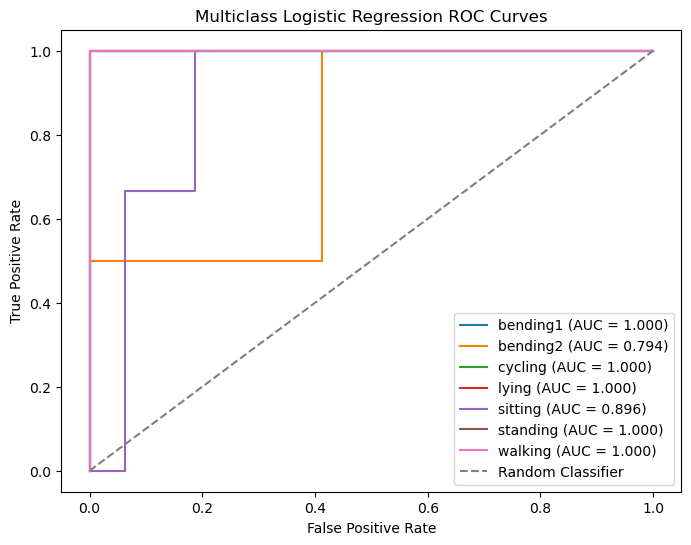

In [87]:
plt.figure(figsize=(8, 6))

multiclass_auc = {}

for i, class_name in enumerate(classes_multi):
    fpr_i, tpr_i, _ = roc_curve(
        y_test_bin[:, i],
        y_test_prob_multi[:, i]
    )

    auc_i = roc_auc_score(
        y_test_bin[:, i],
        y_test_prob_multi[:, i]
    )

    multiclass_auc[class_name] = auc_i

    plt.plot(
        fpr_i,
        tpr_i,
        label=f"{class_name} (AUC = {auc_i:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass Logistic Regression ROC Curves")
plt.legend()
plt.show()

In [88]:
multiclass_auc_df = pd.DataFrame({
    "Activity": multiclass_auc.keys(),
    "AUC": multiclass_auc.values()
})

multiclass_auc_df

,Activity,AUC
0,bending1,1.000000
1,bending2,0.794118
2,cycling,1.000000
3,lying,1.000000
4,sitting,0.895833
5,standing,1.000000
6,walking,1.000000


In [89]:
macro_auc_multi = roc_auc_score(
    y_test_bin,
    y_test_prob_multi,
    average="macro",
    multi_class="ovr"
)

print(
    f"Macro-Average Multiclass AUC: "
    f"{macro_auc_multi:.4f}"
)

Macro-Average Multiclass AUC: 0.9557


The best L1-penalized multinomial logistic regression model was obtained with $l=2$ time-series segments and $C \approx 545.5595$. The mean 4-fold cross-validation accuracy was approximately **0.9273**, with a standard deviation of approximately **0.0260**.

When fitted to the full training set, the model used 84 predictors for each of the seven activity classes. Of the 588 class-specific coefficients, 540 were nonzero. Thus, although an L1 penalty was used, the selected model was not highly sparse. This is consistent with the relatively large selected value of $C$, which corresponds to weak regularization.

On the test set, the model achieved an accuracy of **0.8421**, corresponding to a test error of **0.1579**. The model correctly classified 16 of the 19 test instances.

The confusion matrix shows that `cycling`, `lying`, `standing`, and `walking` were classified perfectly. Both `bending1` test instances were also classified correctly. The three errors consisted of one `bending2` instance classified as `sitting`, one `sitting` instance classified as `bending1`, and one `sitting` instance classified as `standing`.

The one-vs-rest ROC analysis showed strong discrimination overall. The AUC was **1.000** for `bending1`, `cycling`, `lying`, `standing`, and `walking`, while the AUC values for `bending2` and `sitting` were approximately **0.7941** and **0.8958**, respectively. The macro-average multiclass AUC was approximately **0.9557**.

Overall, the multinomial logistic regression model showed strong multiclass discrimination, although `bending2` and `sitting` were more difficult to separate than the other activities.

#### ii. Naive Bayes

The multiclass classification problem is repeated using Naive Bayes classifiers. Both Gaussian Naive Bayes and Multinomial Naive Bayes are considered.

For each classifier, the number of time-series segments $l \in \{1, 2, \ldots, 20\}$ is selected using the same 4-fold stratified cross-validation procedure used in Part 2(c)i.

Gaussian Naive Bayes is applied after standardizing the features. For Multinomial Naive Bayes, the features are transformed using min-max scaling because the model requires nonnegative input values.

In [90]:
def make_gaussian_nb_pipeline():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("naive_bayes", GaussianNB())
    ])

In [91]:
gaussian_nb_results = []

for l in range(1, 21):
    X_l, y_l = build_multiclass_feature_matrix(
        train_files,
        l
    )

    print(f"Processing Gaussian NB: l={l} ({X_l.shape[1]} features)...")

    pipeline = make_gaussian_nb_pipeline()

    scores = cross_val_score(
        pipeline,
        X_l,
        y_l,
        cv=cv_multi,
        scoring="accuracy",
        n_jobs=-1
    )

    gaussian_nb_results.append({
        "l": l,
        "mean_cv_accuracy": scores.mean(),
        "std_cv_accuracy": scores.std()
    })

gaussian_nb_results_df = pd.DataFrame(
    gaussian_nb_results
)

gaussian_nb_results_df

Processing Gaussian NB: l=1 (42 features)...
Processing Gaussian NB: l=2 (84 features)...
Processing Gaussian NB: l=3 (126 features)...
Processing Gaussian NB: l=4 (168 features)...
Processing Gaussian NB: l=5 (210 features)...
Processing Gaussian NB: l=6 (252 features)...
Processing Gaussian NB: l=7 (294 features)...
Processing Gaussian NB: l=8 (336 features)...
Processing Gaussian NB: l=9 (378 features)...
Processing Gaussian NB: l=10 (420 features)...
Processing Gaussian NB: l=11 (462 features)...
Processing Gaussian NB: l=12 (504 features)...
Processing Gaussian NB: l=13 (546 features)...
Processing Gaussian NB: l=14 (588 features)...
Processing Gaussian NB: l=15 (630 features)...
Processing Gaussian NB: l=16 (672 features)...
Processing Gaussian NB: l=17 (714 features)...
Processing Gaussian NB: l=18 (756 features)...
Processing Gaussian NB: l=19 (798 features)...
Processing Gaussian NB: l=20 (840 features)...


,l,mean_cv_accuracy,std_cv_accuracy
0,1,0.841503,0.102863
1,2,0.825980,0.110131
2,3,0.683824,0.123696
3,4,0.695261,0.065416
4,5,0.637255,0.029412
5,6,0.681373,0.064101
6,7,0.624183,0.082221
7,8,0.638072,0.015566
8,9,0.566176,0.081548
9,10,0.637255,0.088235


In [92]:
best_gaussian_nb_result = (
    gaussian_nb_results_df
    .sort_values(
        ["mean_cv_accuracy", "l"],
        ascending=[False, True]
    )
    .iloc[0]
)

best_gaussian_nb_result

l                   1.000000
mean_cv_accuracy    0.841503
std_cv_accuracy     0.102863
Name: 0, dtype: float64

In [93]:
gaussian_nb_results_df.sort_values(
    "mean_cv_accuracy",
    ascending=False
).head(10)

,l,mean_cv_accuracy,std_cv_accuracy
0,1,0.841503,0.102863
1,2,0.825980,0.110131
3,4,0.695261,0.065416
2,3,0.683824,0.123696
5,6,0.681373,0.064101
7,8,0.638072,0.015566
9,10,0.637255,0.088235
4,5,0.637255,0.029412
6,7,0.624183,0.082221
10,11,0.607843,0.079647


In [94]:
def make_multinomial_nb_pipeline():
    return Pipeline([
        ("scaler", MinMaxScaler()),
        ("naive_bayes", MultinomialNB())
    ])

In [95]:
multinomial_nb_results = []

for l in range(1, 21):
    X_l, y_l = build_multiclass_feature_matrix(
        train_files,
        l
    )

    print(f"Processing Multinomial NB: l={l} ({X_l.shape[1]} features)...")

    pipeline = make_multinomial_nb_pipeline()

    scores = cross_val_score(
        pipeline,
        X_l,
        y_l,
        cv=cv_multi,
        scoring="accuracy",
        n_jobs=-1
    )

    multinomial_nb_results.append({
        "l": l,
        "mean_cv_accuracy": scores.mean(),
        "std_cv_accuracy": scores.std()
    })

multinomial_nb_results_df = pd.DataFrame(
    multinomial_nb_results
)

multinomial_nb_results_df

Processing Multinomial NB: l=1 (42 features)...
Processing Multinomial NB: l=2 (84 features)...
Processing Multinomial NB: l=3 (126 features)...
Processing Multinomial NB: l=4 (168 features)...
Processing Multinomial NB: l=5 (210 features)...
Processing Multinomial NB: l=6 (252 features)...
Processing Multinomial NB: l=7 (294 features)...
Processing Multinomial NB: l=8 (336 features)...
Processing Multinomial NB: l=9 (378 features)...
Processing Multinomial NB: l=10 (420 features)...
Processing Multinomial NB: l=11 (462 features)...
Processing Multinomial NB: l=12 (504 features)...
Processing Multinomial NB: l=13 (546 features)...
Processing Multinomial NB: l=14 (588 features)...
Processing Multinomial NB: l=15 (630 features)...
Processing Multinomial NB: l=16 (672 features)...
Processing Multinomial NB: l=17 (714 features)...
Processing Multinomial NB: l=18 (756 features)...
Processing Multinomial NB: l=19 (798 features)...
Processing Multinomial NB: l=20 (840 features)...


,l,mean_cv_accuracy,std_cv_accuracy
0,1,0.741013,0.078750
1,2,0.754085,0.045481
2,3,0.754902,0.056319
3,4,0.739379,0.049040
4,5,0.782680,0.063600
5,6,0.739379,0.049040
6,7,0.754085,0.045481
7,8,0.724673,0.024056
8,9,0.739379,0.025977
9,10,0.754085,0.074355


In [96]:
best_multinomial_nb_result = (
    multinomial_nb_results_df
    .sort_values(
        ["mean_cv_accuracy", "l"],
        ascending=[False, True]
    )
    .iloc[0]
)

best_multinomial_nb_result

l                   5.00000
mean_cv_accuracy    0.78268
std_cv_accuracy     0.06360
Name: 4, dtype: float64

In [97]:
multinomial_nb_results_df.sort_values(
    "mean_cv_accuracy",
    ascending=False
).head(10)

,l,mean_cv_accuracy,std_cv_accuracy
4,5,0.782680,0.063600
2,3,0.754902,0.056319
6,7,0.754085,0.045481
9,10,0.754085,0.074355
1,2,0.754085,0.045481
0,1,0.741013,0.078750
11,12,0.739379,0.064304
3,4,0.739379,0.049040
5,6,0.739379,0.049040
8,9,0.739379,0.025977


In [98]:
nb_cv_comparison = pd.DataFrame({
    "Model": [
        "Gaussian Naive Bayes",
        "Multinomial Naive Bayes"
    ],
    "Best l": [
        int(best_gaussian_nb_result["l"]),
        int(best_multinomial_nb_result["l"])
    ],
    "CV Accuracy": [
        best_gaussian_nb_result["mean_cv_accuracy"],
        best_multinomial_nb_result["mean_cv_accuracy"]
    ],
    "CV Accuracy SD": [
        best_gaussian_nb_result["std_cv_accuracy"],
        best_multinomial_nb_result["std_cv_accuracy"]
    ]
})

nb_cv_comparison

,Model,Best l,CV Accuracy,CV Accuracy SD
0,Gaussian Naive Bayes,1,0.841503,0.102863
1,Multinomial Naive Bayes,5,0.782680,0.063600


Gaussian Naive Bayes achieved its highest cross-validation accuracy with $l=1$, producing a mean accuracy of approximately **0.8415** with a standard deviation of approximately **0.1029**.

Multinomial Naive Bayes achieved its highest cross-validation accuracy with $l=5$, producing a mean accuracy of approximately **0.7827** with a standard deviation of approximately **0.0636**.

Based on cross-validation accuracy, Gaussian Naive Bayes performed better than Multinomial Naive Bayes. The selected value of $l$ is determined separately for each classifier because the two models achieve their best cross-validation performance with different segmentations.

In [99]:
best_l_gaussian = int(best_gaussian_nb_result["l"])
best_l_multinomial = int(best_multinomial_nb_result["l"])

X_train_gaussian, y_train_gaussian = build_multiclass_feature_matrix(
    train_files,
    best_l_gaussian
)

X_train_multinomial, y_train_multinomial = build_multiclass_feature_matrix(
    train_files,
    best_l_multinomial
)

final_gaussian_nb = make_gaussian_nb_pipeline()
final_multinomial_nb = make_multinomial_nb_pipeline()

final_gaussian_nb.fit(
    X_train_gaussian,
    y_train_gaussian
)

final_multinomial_nb.fit(
    X_train_multinomial,
    y_train_multinomial
)

Pipeline(steps=[('scaler', MinMaxScaler()), ('naive_bayes', MultinomialNB())])

In [100]:
X_test_gaussian, y_test_gaussian = build_multiclass_feature_matrix(
    test_files,
    best_l_gaussian
)

X_test_multinomial, y_test_multinomial = build_multiclass_feature_matrix(
    test_files,
    best_l_multinomial
)

print("Gaussian NB test shape:", X_test_gaussian.shape)
print("Multinomial NB test shape:", X_test_multinomial.shape)

Gaussian NB test shape: (19, 42)
Multinomial NB test shape: (19, 210)


In [101]:
y_pred_gaussian = final_gaussian_nb.predict(
    X_test_gaussian
)

y_pred_multinomial = final_multinomial_nb.predict(
    X_test_multinomial
)

gaussian_test_accuracy = (
    y_pred_gaussian == y_test_gaussian
).mean()

multinomial_test_accuracy = (
    y_pred_multinomial == y_test_multinomial
).mean()

gaussian_test_error = 1 - gaussian_test_accuracy
multinomial_test_error = 1 - multinomial_test_accuracy

print(
    f"Gaussian NB Test Accuracy: "
    f"{gaussian_test_accuracy:.4f}"
)
print(
    f"Gaussian NB Test Error: "
    f"{gaussian_test_error:.4f}"
)

print()

print(
    f"Multinomial NB Test Accuracy: "
    f"{multinomial_test_accuracy:.4f}"
)
print(
    f"Multinomial NB Test Error: "
    f"{multinomial_test_error:.4f}"
)

Gaussian NB Test Accuracy: 0.8947
Gaussian NB Test Error: 0.1053

Multinomial NB Test Accuracy: 0.7895
Multinomial NB Test Error: 0.2105


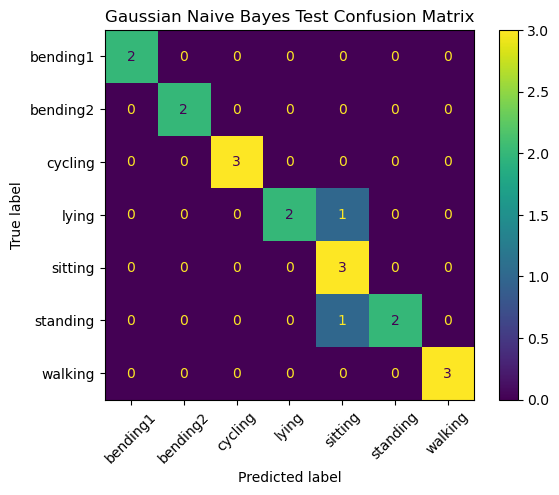

array([[2, 0, 0, 0, 0, 0, 0],
       [0, 2, 0, 0, 0, 0, 0],
       [0, 0, 3, 0, 0, 0, 0],
       [0, 0, 0, 2, 1, 0, 0],
       [0, 0, 0, 0, 3, 0, 0],
       [0, 0, 0, 0, 1, 2, 0],
       [0, 0, 0, 0, 0, 0, 3]])

In [102]:
classes_gaussian = final_gaussian_nb.named_steps[
    "naive_bayes"
].classes_

gaussian_cm = confusion_matrix(
    y_test_gaussian,
    y_pred_gaussian,
    labels=classes_gaussian
)

ConfusionMatrixDisplay(
    confusion_matrix=gaussian_cm,
    display_labels=classes_gaussian
).plot(
    xticks_rotation=45
)

plt.title("Gaussian Naive Bayes Test Confusion Matrix")
plt.show()

gaussian_cm

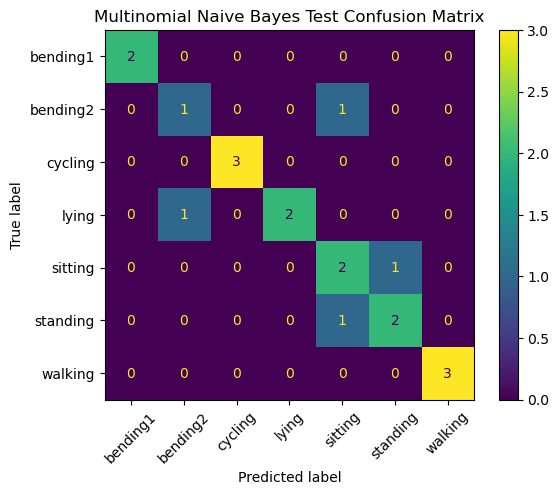

array([[2, 0, 0, 0, 0, 0, 0],
       [0, 1, 0, 0, 1, 0, 0],
       [0, 0, 3, 0, 0, 0, 0],
       [0, 1, 0, 2, 0, 0, 0],
       [0, 0, 0, 0, 2, 1, 0],
       [0, 0, 0, 0, 1, 2, 0],
       [0, 0, 0, 0, 0, 0, 3]])

In [103]:
classes_multinomial = final_multinomial_nb.named_steps[
    "naive_bayes"
].classes_

multinomial_cm = confusion_matrix(
    y_test_multinomial,
    y_pred_multinomial,
    labels=classes_multinomial
)

ConfusionMatrixDisplay(
    confusion_matrix=multinomial_cm,
    display_labels=classes_multinomial
).plot(
    xticks_rotation=45
)

plt.title("Multinomial Naive Bayes Test Confusion Matrix")
plt.show()

multinomial_cm

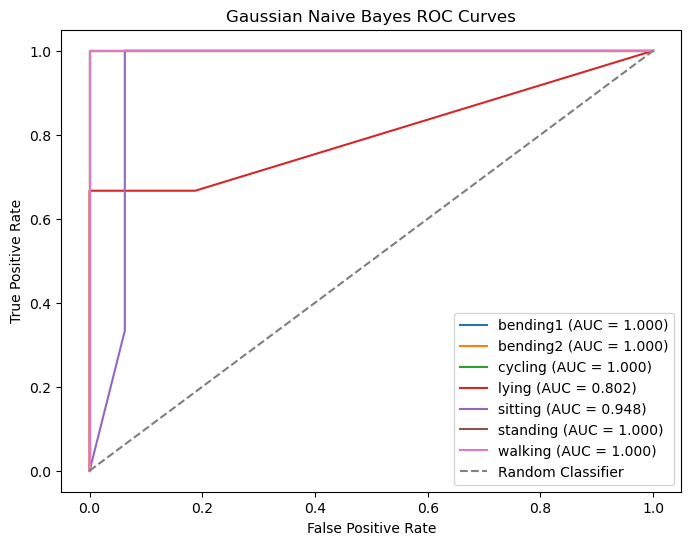

In [104]:
gaussian_test_prob = final_gaussian_nb.predict_proba(
    X_test_gaussian
)

y_test_gaussian_bin = label_binarize(
    y_test_gaussian,
    classes=classes_gaussian
)

gaussian_auc = {}

plt.figure(figsize=(8, 6))

for i, class_name in enumerate(classes_gaussian):
    fpr_i, tpr_i, _ = roc_curve(
        y_test_gaussian_bin[:, i],
        gaussian_test_prob[:, i]
    )

    auc_i = roc_auc_score(
        y_test_gaussian_bin[:, i],
        gaussian_test_prob[:, i]
    )

    gaussian_auc[class_name] = auc_i

    plt.plot(
        fpr_i,
        tpr_i,
        label=f"{class_name} (AUC = {auc_i:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Gaussian Naive Bayes ROC Curves")
plt.legend()
plt.show()

In [105]:
gaussian_auc_df = pd.DataFrame({
    "Activity": gaussian_auc.keys(),
    "AUC": gaussian_auc.values()
})

display(gaussian_auc_df)

gaussian_macro_auc = roc_auc_score(
    y_test_gaussian_bin,
    gaussian_test_prob,
    average="macro",
    multi_class="ovr"
)

print(
    f"Gaussian NB Macro-Average AUC: "
    f"{gaussian_macro_auc:.4f}"
)

,Activity,AUC
0,bending1,1.000000
1,bending2,1.000000
2,cycling,1.000000
3,lying,0.802083
4,sitting,0.947917
5,standing,1.000000
6,walking,1.000000


Gaussian NB Macro-Average AUC: 0.9643


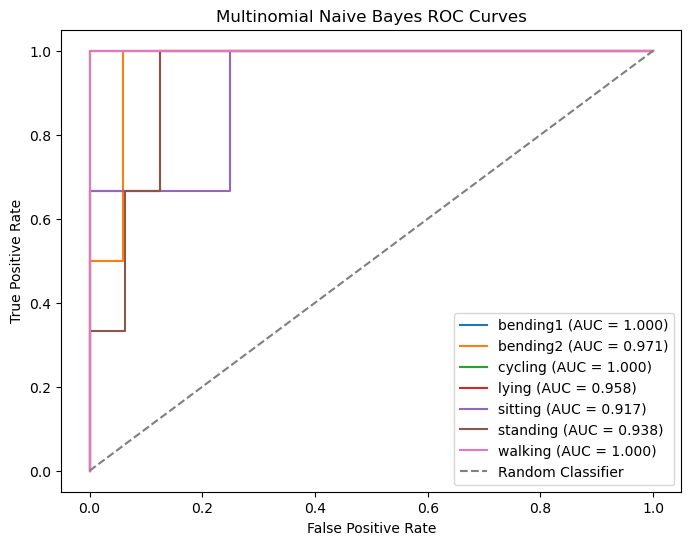

In [106]:
multinomial_test_prob = final_multinomial_nb.predict_proba(
    X_test_multinomial
)

y_test_multinomial_bin = label_binarize(
    y_test_multinomial,
    classes=classes_multinomial
)

multinomial_auc = {}

plt.figure(figsize=(8, 6))

for i, class_name in enumerate(classes_multinomial):
    fpr_i, tpr_i, _ = roc_curve(
        y_test_multinomial_bin[:, i],
        multinomial_test_prob[:, i]
    )

    auc_i = roc_auc_score(
        y_test_multinomial_bin[:, i],
        multinomial_test_prob[:, i]
    )

    multinomial_auc[class_name] = auc_i

    plt.plot(
        fpr_i,
        tpr_i,
        label=f"{class_name} (AUC = {auc_i:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multinomial Naive Bayes ROC Curves")
plt.legend()
plt.show()

In [107]:
multinomial_auc_df = pd.DataFrame({
    "Activity": multinomial_auc.keys(),
    "AUC": multinomial_auc.values()
})

display(multinomial_auc_df)

multinomial_macro_auc = roc_auc_score(
    y_test_multinomial_bin,
    multinomial_test_prob,
    average="macro",
    multi_class="ovr"
)

print(
    f"Multinomial NB Macro-Average AUC: "
    f"{multinomial_macro_auc:.4f}"
)

,Activity,AUC
0,bending1,1.000000
1,bending2,0.970588
2,cycling,1.000000
3,lying,0.958333
4,sitting,0.916667
5,standing,0.937500
6,walking,1.000000


Multinomial NB Macro-Average AUC: 0.9690


In [108]:
nb_test_comparison = pd.DataFrame({
    "Model": [
        "Gaussian Naive Bayes",
        "Multinomial Naive Bayes"
    ],
    "Best l": [
        best_l_gaussian,
        best_l_multinomial
    ],
    "CV Accuracy": [
        best_gaussian_nb_result["mean_cv_accuracy"],
        best_multinomial_nb_result["mean_cv_accuracy"]
    ],
    "Test Accuracy": [
        gaussian_test_accuracy,
        multinomial_test_accuracy
    ],
    "Test Error": [
        gaussian_test_error,
        multinomial_test_error
    ],
    "Macro AUC": [
        gaussian_macro_auc,
        multinomial_macro_auc
    ]
})

nb_test_comparison

,Model,Best l,CV Accuracy,Test Accuracy,Test Error,Macro AUC
0,Gaussian Naive Bayes,1,0.841503,0.894737,0.105263,0.964286
1,Multinomial Naive Bayes,5,0.782680,0.789474,0.210526,0.969013


Gaussian Naive Bayes achieved its best cross-validation performance with $l=1$, with a mean cross-validation accuracy of approximately **0.8415**. On the test set, it achieved an accuracy of **0.8947**, corresponding to a test error of **0.1053**.

The Gaussian Naive Bayes confusion matrix shows that 17 of the 19 test instances were classified correctly. The two errors consisted of one `lying` instance classified as `sitting` and one `standing` instance classified as `sitting`.

Its one-vs-rest ROC analysis also showed strong discrimination. The AUC was **1.000** for `bending1`, `bending2`, `cycling`, `standing`, and `walking`, while the AUC values for `lying` and `sitting` were approximately **0.8021** and **0.9479**, respectively. The macro-average AUC was approximately **0.9643**.

Multinomial Naive Bayes achieved its best cross-validation performance with $l=5$, with a mean cross-validation accuracy of approximately **0.7827**. Its test accuracy was **0.7895**, corresponding to a test error of **0.2105**.

The Multinomial Naive Bayes classifier correctly classified 15 of the 19 test instances. Its errors involved confusion among `bending2`, `lying`, `sitting`, and `standing`.

The Multinomial Naive Bayes model achieved a macro-average AUC of approximately **0.9690**, which was slightly higher than the Gaussian model's macro-average AUC of **0.9643**. However, Gaussian Naive Bayes achieved substantially higher cross-validation and test accuracy and a considerably lower test error.

Therefore, Gaussian Naive Bayes performed better overall than Multinomial Naive Bayes for this multiclass classification problem.

#### iii. Comparison

In [109]:
multiclass_comparison = pd.DataFrame({
    "Model": [
        "L1 Multinomial Logistic Regression",
        "Gaussian Naive Bayes",
        "Multinomial Naive Bayes"
    ],
    "Best l": [
        best_l_multi,
        best_l_gaussian,
        best_l_multinomial
    ],
    "CV Accuracy": [
        best_multiclass_result["mean_cv_accuracy"],
        best_gaussian_nb_result["mean_cv_accuracy"],
        best_multinomial_nb_result["mean_cv_accuracy"]
    ],
    "Test Accuracy": [
        multi_test_accuracy,
        gaussian_test_accuracy,
        multinomial_test_accuracy
    ],
    "Test Error": [
        multi_test_error,
        gaussian_test_error,
        multinomial_test_error
    ],
    "Macro AUC": [
        macro_auc_multi,
        gaussian_macro_auc,
        multinomial_macro_auc
    ]
})

multiclass_comparison

,Model,Best l,CV Accuracy,Test Accuracy,Test Error,Macro AUC
0,L1 Multinomial Logistic Regression,2,0.927288,0.842105,0.157895,0.955707
1,Gaussian Naive Bayes,1,0.841503,0.894737,0.105263,0.964286
2,Multinomial Naive Bayes,5,0.782680,0.789474,0.210526,0.969013


The three multiclass classifiers show different strengths.

The L1-penalized multinomial logistic regression achieved the highest cross-validation accuracy of approximately **0.9273**. However, its test accuracy decreased to **0.8421**, corresponding to a test error of **0.1579**. Its macro-average AUC was approximately **0.9557**.

Gaussian Naive Bayes achieved a lower cross-validation accuracy of approximately **0.8415**, but it produced the best test classification performance. Its test accuracy was approximately **0.8947**, corresponding to the lowest test error of **0.1053**. Its macro-average AUC was also high at approximately **0.9643**.

Multinomial Naive Bayes performed worst in terms of classification accuracy, with a cross-validation accuracy of approximately **0.7827** and a test accuracy of approximately **0.7895**, corresponding to the highest test error of **0.2105**. Although it achieved the highest macro-average AUC of approximately **0.9690**, this advantage was small and did not translate into better classification accuracy.

Therefore, **Gaussian Naive Bayes performed best overall on the test set for this multiclass classification problem**, primarily because it achieved the highest test accuracy and the lowest test error. The L1-penalized multinomial logistic regression showed the strongest cross-validation performance, while Multinomial Naive Bayes achieved the highest macro-average AUC, but neither outperformed Gaussian Naive Bayes on the final test classifications.

## 3. ISLR 4.7.3 (ISLP 4.8.3)

For class $k$,

$$
X \mid Y=k \sim N(\mu_k,\sigma_k^2),
$$

so the class-conditional density is

$$
f_k(x)
=
\frac{1}{\sqrt{2\pi\sigma_k^2}}
\exp\left(
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
\right).
$$

Let $\pi_k$ be the prior probability that an observation belongs to class $k$. By Bayes' theorem,

$$
P(Y=k \mid X=x)
=
\frac{\pi_k f_k(x)}
{\sum_{j=1}^{K}\pi_j f_j(x)}.
$$

Since the denominator is the same for every class, the Bayes classifier assigns an observation to the class that maximizes

$$
\pi_k f_k(x).
$$

Taking the logarithm and dropping terms that are constant across classes gives the discriminant function

$$
\delta_k(x)
=
-\frac{1}{2}\log(\sigma_k^2)
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
+\log(\pi_k).
$$

Expanding the squared term,

$$
\delta_k(x)
=
-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_k}{\sigma_k^2}x
-\frac{\mu_k^2}{2\sigma_k^2}
-\frac{1}{2}\log(\sigma_k^2)
+\log(\pi_k).
$$

Therefore, the discriminant function has the form

$$
\delta_k(x)=A_kx^2+B_kx+C_k,
$$

where

$$
A_k=-\frac{1}{2\sigma_k^2}.
$$

Unlike LDA, QDA does not assume that

$$
\sigma_1^2=\sigma_2^2=\cdots=\sigma_K^2.
$$

Therefore, the coefficient of $x^2$ generally differs across classes and does not cancel when two discriminant functions are compared. For classes $k$ and $l$, the decision boundary satisfies

$$
\delta_k(x)=\delta_l(x),
$$

which gives an equation of the form

$$
\left(
-\frac{1}{2\sigma_k^2}
+\frac{1}{2\sigma_l^2}
\right)x^2
+
\left(
\frac{\mu_k}{\sigma_k^2}
-\frac{\mu_l}{\sigma_l^2}
\right)x
+
C
=0.
$$

Since $\sigma_k^2$ and $\sigma_l^2$ are generally different, the coefficient of $x^2$ is nonzero. Hence, the Bayes decision boundary is quadratic rather than linear.


Thus, in this case, the Bayes classifier is **not linear; it is quadratic**.

## 4. ISLR 4.7.7 (ISLP 4.8.7)

Let $Y$ denote that a company issues a dividend and $N$ denote that it does not. The given prior probabilities are

$$
P(Y)=0.8,
\qquad
P(N)=0.2.
$$

For companies that issue a dividend,

$$
X \mid Y \sim N(10,36),
$$

and for companies that do not,

$$
X \mid N \sim N(0,36).
$$

Using the normal density,

$$
f(x)
=
\frac{1}{\sqrt{2\pi\sigma^2}}
\exp\left(
-\frac{(x-\mu)^2}{2\sigma^2}
\right),
$$

the conditional densities at $X=4$ are

$$
f_Y(4)
=
\frac{1}{\sqrt{72\pi}}
\exp\left(
-\frac{(4-10)^2}{72}
\right)
=
\frac{1}{\sqrt{72\pi}}e^{-1/2},
$$

and

$$
f_N(4)
=
\frac{1}{\sqrt{72\pi}}
\exp\left(
-\frac{(4-0)^2}{72}
\right)
=
\frac{1}{\sqrt{72\pi}}e^{-2/9}.
$$

By Bayes' theorem,

$$
P(Y \mid X=4)
=
\frac{P(Y)f_Y(4)}
{P(Y)f_Y(4)+P(N)f_N(4)}.
$$

Substituting the values,

$$
P(Y \mid X=4)
=
\frac{
0.8\left(\frac{1}{\sqrt{72\pi}}e^{-1/2}\right)
}{
0.8\left(\frac{1}{\sqrt{72\pi}}e^{-1/2}\right)
+
0.2\left(\frac{1}{\sqrt{72\pi}}e^{-2/9}\right)
}.
$$

The common factor $\frac{1}{\sqrt{72\pi}}$ cancels, giving

$$
P(Y \mid X=4)
=
\frac{0.8e^{-1/2}}
{0.8e^{-1/2}+0.2e^{-2/9}}
\approx 0.752.
$$

Therefore, the probability that the company will issue a dividend given that its percentage profit last year was $X=4$ is approximately

$$
\boxed{0.752}
$$

or **75.2%**.

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9